# Fashion-MNIST: training seeds 42, 43, 44

Default: **five models × three seeds = 15 runs**.

## Run on Colab
1. Select a GPU. Run the configuration, data, utility and model-definition cells.
2. Run both training-group cells (Linear/MLP/CNN; LSTM/Transformer).
3. Run the aggregation and plotting cells to export metrics and report figures.

Configuration is in the import cell: TRAIN_SEEDS=[42,43,44], TRAIN_MODELS=True,
FORCE_RETRAIN=False. Completed runs are skipped after metadata validation. An
interrupted run that has not saved a final checkpoint must restart from scratch.
To evaluate only, set TRAIN_MODELS=False.

## Optional dropout ablation
Set RUN_VARIANTS=["Baseline","NoDropout"] for twelve additional runs. Linear is
excluded from NoDropout because it already contains no dropout. All standalone,
LSTM inter-layer and attention dropout are disabled in the ablated variant;
normalization remains unchanged. The final section reports paired differences
within each seed and their mean/std, without presuming an improvement.

## Output
Each model/variant/seed has a separate filename, for example
`CNN_200K_v4_Baseline_seed42.pt` or `CNN_200K_v4_NoDropout_seed43.pt`.
Persistent results are under `multiseed_42_43_44`; runtime report-image exports
are under `/content/fmnist_multiseed_42_43_44`.
CSV files include raw per-seed results, numeric mean/std columns, formatted report
tables, per-class statistics, and optional paired-ablation statistics.


In [1]:
import json, os, sys, subprocess
INSTALL_CONFIG_PATH = '/content/fmnist_install_config.json'
if os.path.isfile(INSTALL_CONFIG_PATH):
  with open(INSTALL_CONFIG_PATH) as stream:
    install_config = json.load(stream)
  packages = install_config['packages']
  recorded_python = install_config.get('python_version')
  if recorded_python:
    print('Recorded Python:', recorded_python, '| Current:', sys.version.split()[0])
  print('Installing package versions from:', INSTALL_CONFIG_PATH)
else:
  packages = ['torch', 'torchvision', 'scikit-learn', 'matplotlib', 'pandas', 'numpy', 'Pillow']
  install_config = {}
  print('No install config found; installing the original notebook dependencies.')
if not isinstance(packages, list) or not packages or not all(isinstance(p, str) and p and not p.startswith('-') for p in packages):
  raise ValueError('Install config must contain a nonempty list of package specifications.')
command = [sys.executable, '-m', 'pip', 'install', '-q', *packages]
if install_config.get('extra_index_url'):
  command += ['--extra-index-url', install_config['extra_index_url']]
subprocess.check_call(command)
print('If already-imported packages changed, restart the Colab session before continuing.')

Recorded Python: 3.13.16 | Current: 3.13.16
Installing package versions from: /content/fmnist_install_config.json
If already-imported packages changed, restart the Colab session before continuing.


In [2]:
import os, time, copy, random, json, hashlib, gc
from collections import Counter
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
SPLIT_SEED = 42
TRAIN_SEEDS = [42,43,44]
SEED = SPLIT_SEED
RUN_VARIANTS = ["Baseline", "NoDropout"]
TRAIN_MODELS = True
FORCE_RETRAIN = False
RE_EVALUATE = True
EPOCHS = 200
LR = 1e-3
PATIENCE = 8
NUM_WORKERS = 2
EVAL_BATCH_SIZE = 256
REQUIRE_ALL_SEEDS = True
if not RUN_VARIANTS or len(RUN_VARIANTS) != len(set(RUN_VARIANTS)):
  raise ValueError("RUN_VARIANTS must be nonempty and unique.")
if not set(RUN_VARIANTS).issubset({"Baseline", "NoDropout"}):
  raise ValueError("Supported variants: Baseline, NoDropout.")
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 0.1 Mount Google Drive and set up output folders

In [3]:
USE_GITHUB = True
if USE_GITHUB:
  REPO_URL = (
    "https://github.com/shomin2155vn/"
    "CO3133-Semester-261-Group-07-Assignments.git"
  )
  REPO_BRANCH = "main"
  REPO_DIR = (
    "/content/fmnist_repo"
    if os.path.isdir("/content")
    else os.path.abspath("fmnist_repo")
  )

  if not os.path.exists(REPO_DIR):
    subprocess.run(
      [
        "git", "clone",
        "--depth", "1",
        "--branch", REPO_BRANCH,
        REPO_URL,
        REPO_DIR,
      ],
      check=True,
    )
  elif not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    raise RuntimeError(
      f"{REPO_DIR} already exists but is not a Git repository. "
      "Choose another REPO_DIR."
    )
  else:
    print("Reusing existing local clone:", REPO_DIR)

  OUTPUT_DIR = os.path.join(
    REPO_DIR,
    "Assignment1",
    "Reproducibility",
  )
  MULTISEED_DIR = os.path.join(
    OUTPUT_DIR,
    "multiseed_42_43_44",
  )
  if not os.path.isdir(
    os.path.join(MULTISEED_DIR, "checkpoints")
  ):
    raise FileNotFoundError(
      "Checkpoint folder was not found in the cloned repository: "
      + os.path.join(MULTISEED_DIR, "checkpoints")
    )
else:
  try:
    from google.colab import drive

    drive.mount("/content/drive")
    DRIVE_ROOT = (
      "/content/drive/MyDrive/CO3133_Assignments"
    )
  except ImportError:
    DRIVE_ROOT = "."

  OUTPUT_DIR = os.path.join(
    DRIVE_ROOT,
    "A1_Foundations_FashionMNIST",
  )
  MULTISEED_DIR = os.path.join(
    OUTPUT_DIR,
    "multiseed_42_43_44",
  )
CKPT_DIR = os.path.join(MULTISEED_DIR, "checkpoints")
FIG_DIR = os.path.join(MULTISEED_DIR, "figures")
RESULTS_DIR = os.path.join(MULTISEED_DIR, "results")

RUNTIME_FIG_DIR = (
  "/content/fmnist_multiseed_42_43_44"
  if os.path.isdir("/content")
  else os.path.abspath("fmnist_multiseed_42_43_44")
)
for directory in (
  CKPT_DIR,
  FIG_DIR,
  RESULTS_DIR,
  RUNTIME_FIG_DIR,
):
  os.makedirs(directory, exist_ok=True)
print("Source:", "GitHub" if USE_GITHUB else "Google Drive/local")
print("Training seeds:", TRAIN_SEEDS)
print("Fixed split seed:", SPLIT_SEED)
print("Variants:", RUN_VARIANTS)
print("Checkpoints:", CKPT_DIR)
print("Results:", RESULTS_DIR)
print("Runtime report images:", RUNTIME_FIG_DIR)

Source: GitHub
Training seeds: [42, 43, 44]
Fixed split seed: 42
Variants: ['Baseline', 'NoDropout']
Checkpoints: /content/fmnist_repo/Assignment1/Reproducibility/multiseed_42_43_44/checkpoints
Results: /content/fmnist_repo/Assignment1/Reproducibility/multiseed_42_43_44/results
Runtime report images: /content/fmnist_multiseed_42_43_44


In [4]:
import platform
env_info = {
  "split_seed": SPLIT_SEED, "training_seeds": TRAIN_SEEDS,
  "python_version": platform.python_version(),
  "torch_version": torch.__version__,
  "torchvision_version": torchvision.__version__,
  "device": str(DEVICE),
  "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A (CPU run)",
  "platform": platform.platform(),
}
for k, v in env_info.items():
  print(f"{k}: {v}")


split_seed: 42
training_seeds: [42, 43, 44]
python_version: 3.13.16
torch_version: 2.11.0+cu130
torchvision_version: 0.26.0+cu130
device: cuda
gpu_name: Tesla T4
platform: Linux-6.6.159+-x86_64-with-glibc2.39


## 1. Data loading



In [5]:
mnist_debug_train = torchvision.datasets.MNIST(root="./data", train=True, download=True)
print("MNIST debug set:", len(mnist_debug_train), "images")
fmnist_train_raw = torchvision.datasets.FashionMNIST(
  root="./data", train=True, download=True
)
fmnist_test_raw = torchvision.datasets.FashionMNIST(
  root="./data", train=False, download=True
)
print("Official train pool:", len(fmnist_train_raw))
print("Official test set:", len(fmnist_test_raw))
train_images_all = fmnist_train_raw.data.numpy()
train_labels_all = fmnist_train_raw.targets.numpy()
test_images = fmnist_test_raw.data.numpy()
test_labels = fmnist_test_raw.targets.numpy()
assert train_images_all.shape == (60_000, 28, 28), "Unexpected official training-pool shape"
assert train_labels_all.shape == (60_000,), "Image/label count mismatch"
assert train_images_all.dtype == np.uint8, "Expected raw uint8 pixels"
assert np.isfinite(train_images_all).all(), "Non-finite pixel detected"
assert np.array_equal(np.unique(train_labels_all), np.arange(10)), "Labels must cover integers 0 through 9"
assert test_images.shape == (10_000, 28, 28), "Unexpected official test-pool shape"
assert test_labels.shape == (10_000,), "Image/label count mismatch"
assert test_images.dtype == np.uint8, "Expected raw uint8 pixels"
assert np.isfinite(test_images).all(), "Non-finite pixel detected"
assert np.array_equal(np.unique(test_labels), np.arange(10)), "Labels must cover integers 0 through 9"

train_idx, val_idx = train_test_split(
  np.arange(len(train_labels_all)),
  test_size=0.2,
  stratify=train_labels_all,
  random_state=SPLIT_SEED,
)
train_images, train_labels = train_images_all[train_idx], train_labels_all[train_idx]
val_images, val_labels = train_images_all[val_idx], train_labels_all[val_idx]

print("Official training pool:", train_images_all.shape, train_labels_all.shape)
print(f"Development split: train={len(train_images):,}, val={len(val_images):,}, split_seed={SPLIT_SEED}")

DATA_SIGNATURE = hashlib.sha256(
  np.asarray(train_idx, dtype=np.int64).tobytes()
  + np.asarray(val_idx, dtype=np.int64).tobytes()
  + np.asarray(test_labels, dtype=np.int64).tobytes()
).hexdigest()
print("Fixed split signature:", DATA_SIGNATURE)


100%|██████████| 9.91M/9.91M [00:00<00:00, 16.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 501kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.73MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.1MB/s]


MNIST debug set: 60000 images


100%|██████████| 26.4M/26.4M [00:02<00:00, 13.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.85MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 20.8MB/s]


Official train pool: 60000
Official test set: 10000
Official training pool: (60000, 28, 28) (60000,)
Development split: train=48,000, val=12,000, split_seed=42
Fixed split signature: 7a18ccb7286c589df2310f783f01b4fe6238ea26a3e5cc500436c54d9a10934c


## 2. Exploratory Data Analysis (EDA)




In [6]:
class_ids, counts = np.unique(train_labels, return_counts=True)
CLASS_NAMES = list(fmnist_train_raw.classes)
NUM_CLASSES = len(class_ids)
if len(CLASS_NAMES) != NUM_CLASSES:
  raise ValueError("Dataset class names do not match the labels found in the training data.")
print(f"Detected {NUM_CLASSES} classes from the training data.")
h, w = train_images.shape[1:]
assert train_images.shape[1:] == (28, 28), "Training image shape mismatch!"
assert not np.isnan(train_images).any(), "Corrupted NaN pixel detected in training split!"
def get_dir_size_mb(path):
  total = 0
  if os.path.exists(path):
    for root, _, files in os.walk(path):
      for f in files:
        total += os.path.getsize(os.path.join(root, f))
  return total / 1e6

data_size_mb = get_dir_size_mb("./data")

print(f"Official dataset metadata: {len(fmnist_train_raw):,} train-pool + {len(fmnist_test_raw):,} test samples")
print(f"Training samples         : {len(train_images):,} samples")
print(f"Validation samples       : {len(val_images):,} samples")
print(f"Input dimensions         : {h} x {w} x 1 (grayscale), dtype: {train_images.dtype}, range: [{train_images.min()}, {train_images.max()}]")
print(f"Current local cache size : {data_size_mb:.1f} MB")

Detected 10 classes from the training data.
Official dataset metadata: 60,000 train-pool + 10,000 test samples
Training samples         : 48,000 samples
Validation samples       : 12,000 samples
Input dimensions         : 28 x 28 x 1 (grayscale), dtype: uint8, range: [0, 255]
Current local cache size : 152.4 MB


Class distribution summary:
 class_id  class_name  train_count  train_pct  validation_count  validation_pct
        0 T-shirt/top         4800       10.0              1200            10.0
        1     Trouser         4800       10.0              1200            10.0
        2    Pullover         4800       10.0              1200            10.0
        3       Dress         4800       10.0              1200            10.0
        4        Coat         4800       10.0              1200            10.0
        5      Sandal         4800       10.0              1200            10.0
        6       Shirt         4800       10.0              1200            10.0
        7     Sneaker         4800       10.0              1200            10.0
        8         Bag         4800       10.0              1200            10.0
        9  Ankle boot         4800       10.0              1200            10.0

Max/min class count ratio (imbalance ratio): 1.0000
Perfectly balanced across classes: True

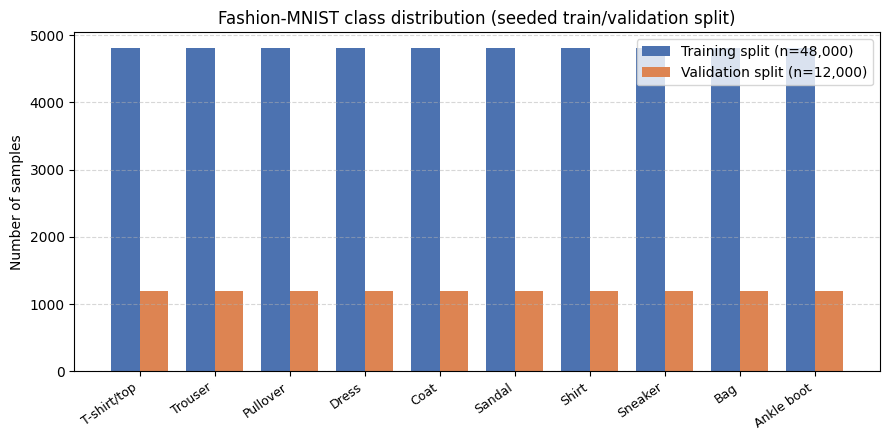

In [7]:
val_counts = np.bincount(val_labels, minlength=NUM_CLASSES)

dist_df = pd.DataFrame({
  "class_id": class_ids,
  "class_name": CLASS_NAMES,
  "train_count": counts,
  "train_pct": 100 * counts / counts.sum(),
  "validation_count": val_counts,
  "validation_pct": 100 * val_counts / val_counts.sum(),
})
print("Class distribution summary:")
print(dist_df.to_string(index=False))
imbalance_ratio = dist_df['train_count'].max() / dist_df['train_count'].min()
is_balanced = (counts.std() == 0) and (val_counts.std() == 0)
print(f"\nMax/min class count ratio (imbalance ratio): {imbalance_ratio:.4f}")
print(f"Perfectly balanced across classes: {is_balanced} (std = {counts.std():.1f})")
x = np.arange(NUM_CLASSES)
width = 0.38
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(x - width/2, counts, width, label=f"Training split (n={counts.sum():,})", color="#4C72B0")
ax.bar(x + width/2, val_counts, width, label=f"Validation split (n={val_counts.sum():,})", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=35, ha="right", fontsize=9)
ax.set_ylabel("Number of samples")
ax.set_title("Fashion-MNIST class distribution (seeded train/validation split)")
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "01_eda_class_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

Raw pixel mean (0-255)  = 72.99, std = 90.06
Normalized mean [0-1]   = 0.2863, std = 0.3532
Fraction of background (value = 0) pixels = 50.2%


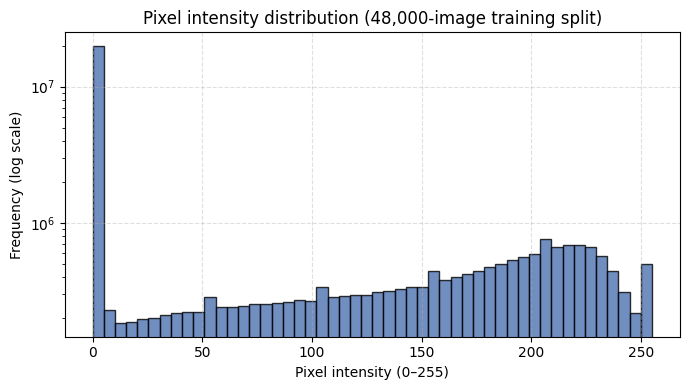

In [8]:
raw_mean = float(train_images.mean())
raw_std = float(train_images.std())
bg_frac = float((train_images == 0).mean())
print(f"Raw pixel mean (0-255)  = {raw_mean:.2f}, std = {raw_std:.2f}")
print(f"Normalized mean [0-1]   = {raw_mean / 255.0:.4f}, std = {raw_std / 255.0:.4f}")
print(f"Fraction of background (value = 0) pixels = {bg_frac * 100:.1f}%")
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train_images.flatten(), bins=50, color="#4C72B0", edgecolor="black", alpha=0.8)
ax.set_yscale("log")
ax.set_xlabel("Pixel intensity (0–255)")
ax.set_ylabel("Frequency (log scale)")
ax.set_title("Pixel intensity distribution (48,000-image training split)")
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "01_eda_pixel_intensity.png"), dpi=150, bbox_inches="tight")
plt.show()

In [9]:
per_class_mean = [float(train_images[train_labels == c].mean()) for c in range(NUM_CLASSES)]
intensity_df = pd.DataFrame({
  "class_id": range(NUM_CLASSES),
  "class_name": CLASS_NAMES,
  "mean_pixel_intensity": per_class_mean
}).sort_values(by="mean_pixel_intensity", ascending=True)
print("Per-class mean pixel intensity:")
print(intensity_df.to_string(index=False))
print(f"\nObservation: Footwear (Sandal: {per_class_mean[5]:.2f}, Sneaker: {per_class_mean[7]:.2f}) has low mean intensity due to wide empty margins,")
print(f"while heavy upper garments (Pullover: {per_class_mean[2]:.2f}, Coat: {per_class_mean[4]:.2f}) have high intensity as they fill most of the 28x28 frame.")

Per-class mean pixel intensity:
 class_id  class_name  mean_pixel_intensity
        5      Sandal             34.800133
        7     Sneaker             42.837788
        1     Trouser             56.987135
        3       Dress             66.121778
        9  Ankle boot             76.760902
        0 T-shirt/top             82.849735
        6       Shirt             84.826124
        8         Bag             90.169411
        2    Pullover             96.491521
        4        Coat             98.100238

Observation: Footwear (Sandal: 34.80, Sneaker: 42.84) has low mean intensity due to wide empty margins,
while heavy upper garments (Pullover: 96.49, Coat: 98.10) have high intensity as they fill most of the 28x28 frame.


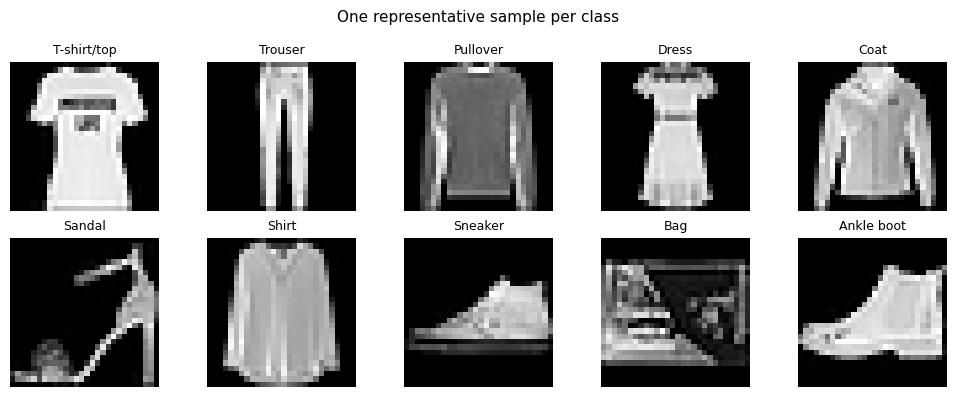

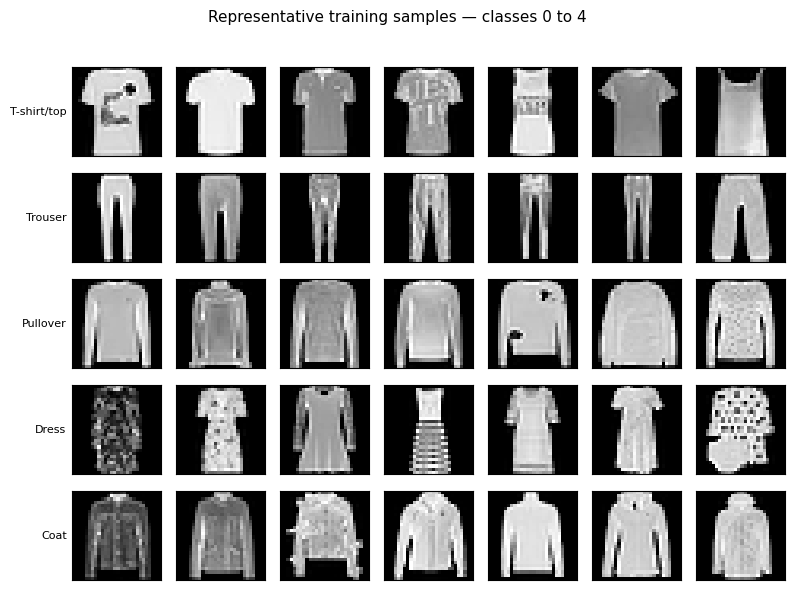

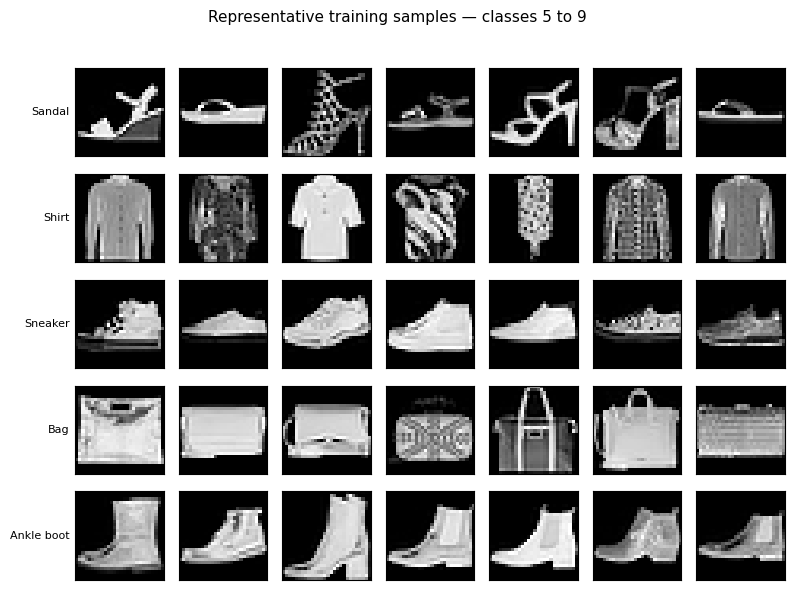

Training-only pixel mean = 0.2863, pixel std = 0.3532


In [10]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for c in range(NUM_CLASSES):
  idx = np.where(train_labels == c)[0][0]
  ax = axes[c // 5, c % 5]
  ax.imshow(train_images[idx], cmap="gray")
  ax.set_title(CLASS_NAMES[c], fontsize=9)
  ax.axis("off")
plt.suptitle("One representative sample per class", fontsize=11)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "01_eda_representative_samples.png"), dpi=150, bbox_inches="tight")
plt.show()
rng_eda = np.random.default_rng(SEED)
N_PER_CLASS = 7
CLASS_GROUPS = [range(0, 5), range(5, 10)]

for g, class_group in enumerate(CLASS_GROUPS, start=1):
  class_group = list(class_group)
  fig, axes = plt.subplots(len(class_group), N_PER_CLASS,
               figsize=(N_PER_CLASS * 1.15, len(class_group) * 1.15))
  for row, c in enumerate(class_group):
    idxs = np.where(train_labels == c)[0]
    chosen = rng_eda.choice(idxs, size=N_PER_CLASS, replace=False)
    for j, idx in enumerate(chosen):
      ax = axes[row, j]
      ax.imshow(train_images[idx], cmap="gray", vmin=0, vmax=255)
      ax.set_xticks([]); ax.set_yticks([])
      if j == 0:
        ax.set_ylabel(CLASS_NAMES[c], fontsize=8, rotation=0, ha="right", va="center")
  plt.suptitle(f"Representative training samples — classes {class_group[0]} to {class_group[-1]}",
         y=1.02, fontsize=11)
  plt.tight_layout()
  plt.savefig(os.path.join(FIG_DIR, f"01_eda_samples_classes_{class_group[0]}-{class_group[-1]}.png"), dpi=150, bbox_inches="tight")
  plt.show()

pixel_mean = float((train_images / 255.0).mean())
pixel_std = float((train_images / 255.0).std())
print(f"Training-only pixel mean = {pixel_mean:.4f}, pixel std = {pixel_std:.4f}")

In [11]:
assert len(train_images) == 48_000 and len(val_images) == 12_000
assert np.all(np.bincount(train_labels, minlength=10) == 4_800)
assert np.all(np.bincount(val_labels, minlength=10) == 1_200)
print(f"train: {train_images.shape[0]} | val: {val_images.shape[0]} | official test: {len(fmnist_test_raw)}")
print("Split seed:", SEED, "| Stratified by label: yes | Split unit: one image = one sample")
print(f"Normalization mean = {pixel_mean:.4f}, std = {pixel_std:.4f} (training split only)")

train: 48000 | val: 12000 | official test: 10000
Split seed: 42 | Stratified by label: yes | Split unit: one image = one sample
Normalization mean = 0.2863, std = 0.3532 (training split only)


## 4. Preprocessing, Dataset and DataLoader




In [12]:
class ArrayImageDataset(Dataset):
  def __init__(self, images, labels, transform):
    self.images = images
    self.labels = labels
    self.transform = transform
  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    img = Image.fromarray(self.images[idx]).convert("L")
    label = int(self.labels[idx])
    return self.transform(img), label
train_transform = transforms.Compose([
  transforms.RandomRotation(degrees=(-10, 10)),
  transforms.RandomHorizontalFlip(p=0.5),
  transforms.RandomCrop(size=28, padding=2),
  transforms.ToTensor(),
  transforms.Normalize((pixel_mean,), (pixel_std,)),
])
eval_transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize((pixel_mean,), (pixel_std,)),
])
BATCH_SIZE = 128
train_ds = ArrayImageDataset(train_images, train_labels, train_transform)
val_ds = ArrayImageDataset(val_images, val_labels, eval_transform)
test_ds = ArrayImageDataset(test_images, test_labels, eval_transform)

def seed_worker(worker_id):
  worker_seed = torch.initial_seed() % (2**32)
  np.random.seed(worker_seed)
  random.seed(worker_seed)

def make_loaders():
  train = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    drop_last=False,
    worker_init_fn=seed_worker,
  )
  val = DataLoader(
    val_ds,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
  )
  test = DataLoader(
    test_ds,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    worker_init_fn=seed_worker,
  )
  return train, val, test

train_loader, val_loader, test_loader = make_loaders()
xb, yb = next(iter(train_loader))
print("One preprocessed batch image shape:", xb.shape)
print("One preprocessed batch label shape:", yb.shape)

One preprocessed batch image shape: torch.Size([128, 1, 28, 28])
One preprocessed batch label shape: torch.Size([128])


## 5. Shared training / evaluation utilities



In [13]:
def count_params(model):
  return sum(p.numel() for p in model.parameters() if p.requires_grad)

def compute_class_metrics(y_true, y_pred, class_names=CLASS_NAMES):
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)
  labels = np.arange(len(class_names))

  prec_per_class = precision_score(
    y_true, y_pred, labels=labels,
    average=None, zero_division=0
  )
  rec_per_class = recall_score(
    y_true, y_pred, labels=labels,
    average=None, zero_division=0
  )
  f1_per_class = f1_score(
    y_true, y_pred, labels=labels,
    average=None, zero_division=0
  )

  rows = []
  for c in labels:
    acc_c = ((y_pred == c) == (y_true == c)).mean()
    support_c = (y_true == c).sum()

    rows.append({
      "Class ID": int(c),
      "Class Name": class_names[c],
      "Accuracy": float(acc_c),
      "Precision": float(prec_per_class[c]),
      "Recall": float(rec_per_class[c]),
      "F1-Score": float(f1_per_class[c]),
      "Support": int(support_c),
    })

  return pd.DataFrame(rows)

def fit(model, dataloader, criterion, optimizer, device=DEVICE):
  model.train()
  running_loss = 0.0
  all_preds, all_labels = [], []

  for images, labels in dataloader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()
    running_loss += loss.item() * images.size(0)
    all_preds.append(outputs.argmax(dim=1).detach().cpu().numpy())
    all_labels.append(labels.detach().cpu().numpy())

  y_pred = np.concatenate(all_preds)
  y_true = np.concatenate(all_labels)
  epoch_loss = running_loss / len(dataloader.dataset)
  acc = accuracy_score(y_true, y_pred)
  prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
  rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
  macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

  return epoch_loss, acc, prec, rec, macro_f1, y_true, y_pred

@torch.no_grad()
def evaluate(model, dataloader, criterion, device=DEVICE):
  model.eval()
  running_loss = 0.0
  all_preds, all_labels = [], []
  for images, labels in dataloader:
    images = images.to(device)
    labels = labels.to(device)
    outputs = model(images)
    loss = criterion(outputs, labels)

    running_loss += loss.item() * images.size(0)
    all_preds.append(outputs.argmax(dim=1).detach().cpu().numpy())
    all_labels.append(labels.detach().cpu().numpy())

  y_pred = np.concatenate(all_preds)
  y_true = np.concatenate(all_labels)
  epoch_loss = running_loss / len(dataloader.dataset)
  acc = accuracy_score(y_true, y_pred)
  prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
  rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
  macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

  return epoch_loss, acc, prec, rec, macro_f1, y_true, y_pred


def run_one_epoch(model, train_loader, val_loader, criterion, optimizer, device=DEVICE):
  train_loss, train_acc, train_prec, train_rec, train_f1, _, _ = fit(model, train_loader, criterion, optimizer, device)
  val_loss, val_acc, val_prec, val_rec, val_f1, _, _ = evaluate(model, val_loader, criterion, device)
  return (train_loss, train_acc, train_prec, train_rec, train_f1,
      val_loss, val_acc, val_prec, val_rec, val_f1)


def run_epoch(model, loader, criterion, optimizer=None, desc=None):
  if optimizer is not None:
    return fit(model, loader, criterion, optimizer, DEVICE)
  else:
    return evaluate(model, loader, criterion, DEVICE)


def train_model(model, name, epochs=15, lr=1e-3, patience=3, history=None,
        optimizer_state_dict=None, scheduler_state_dict=None,
        best_val_loss=None, start_epoch=None):
  model = model.to(DEVICE)
  criterion = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, threshold=1e-4,
    threshold_mode="abs", min_lr=1e-6
  )

  if optimizer_state_dict is not None:
    optimizer.load_state_dict(optimizer_state_dict)
  if scheduler_state_dict is not None:
    scheduler.load_state_dict(scheduler_state_dict)

  if history is None:
    history = {"train_loss": [], "train_acc": [], "train_prec": [], "train_rec": [], "train_f1": [],
          "val_loss": [], "val_acc": [], "val_prec": [], "val_rec": [], "val_f1": []}
  else:
    history = copy.deepcopy(history)

  history.setdefault("epoch_time_sec", [])
  start_epoch = len(history.get("train_loss", [])) if start_epoch is None else int(start_epoch)
  if best_val_loss is None:
    best_val_loss = min(history.get("val_loss", [])) if history.get("val_loss") else float("inf")

  best_state = copy.deepcopy(model.state_dict())
  best_optimizer_state = copy.deepcopy(optimizer.state_dict())
  best_scheduler_state = copy.deepcopy(scheduler.state_dict())
  bad_epochs = 0

  t0 = time.time()
  for local_epoch in range(1, epochs + 1):
    if DEVICE.type == "cuda":
      torch.cuda.synchronize(DEVICE)
    epoch_start = time.perf_counter()
    train_loss, train_acc, train_prec, train_rec, train_f1, val_loss, val_acc, val_prec, val_rec, val_f1 = run_one_epoch(
      model, train_loader, val_loader, criterion, optimizer, DEVICE
    )
    scheduler.step(val_loss)

    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["train_prec"].append(train_prec); history["train_rec"].append(train_rec); history["train_f1"].append(train_f1)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    history["val_prec"].append(val_prec); history["val_rec"].append(val_rec); history["val_f1"].append(val_f1)

    epoch = start_epoch + local_epoch
    if DEVICE.type == "cuda":
      torch.cuda.synchronize(DEVICE)
    epoch_time = time.perf_counter() - epoch_start
    history["epoch_time_sec"].append(epoch_time)
    print(f"[{name}] Epoch {epoch:03d} | Train Loss: {train_loss:.4f} - Acc: {train_acc:.4f} - F1: {train_f1:.4f} | "
       f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.4f} - F1: {val_f1:.4f} | LR: {optimizer.param_groups[0]['lr']:.2e} - Epoch time: {epoch_time:.2f}s")

    if val_loss < best_val_loss:
      best_val_loss = val_loss
      best_state = copy.deepcopy(model.state_dict())
      best_optimizer_state = copy.deepcopy(optimizer.state_dict())
      best_scheduler_state = copy.deepcopy(scheduler.state_dict())
      bad_epochs = 0
    else:
      bad_epochs += 1
      if bad_epochs >= patience:
        print(f"[{name}] early stopping at epoch {epoch} (best val_loss={best_val_loss:.4f})")
        break

  train_time = time.time() - t0
  model.load_state_dict(best_state)
  optimizer.load_state_dict(best_optimizer_state)
  scheduler.load_state_dict(best_scheduler_state)
  training_state = {
    "optimizer_state_dict": optimizer.state_dict(),
    "scheduler_state_dict": scheduler.state_dict(),
    "best_val_loss": float(best_val_loss),
    "best_epoch": int(np.argmin(history["val_loss"])) + 1,
    "epochs_run": len(history.get("train_loss", [])),
  }
  return model, history, train_time, training_state

def measure_inference_time(model, loader, n_warmup_batches=2):
  model.eval()
  device_sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)

  with torch.no_grad():
    for i, (xb, _) in enumerate(loader):
      if i >= n_warmup_batches:
        break
      _ = model(xb.to(DEVICE))
  device_sync()
  t0 = time.time()
  with torch.no_grad():
    for xb, _ in loader:
      xb = xb.to(DEVICE)
      _ = model(xb)
  device_sync()
  total_time = time.time() - t0
  return 1000 * total_time / len(loader.dataset)


## 6. Model 1 — Linear / Softmax classifier




In [14]:
class LinearClassifier(nn.Module):
  def __init__(self, num_classes=NUM_CLASSES, input_dim=28 * 28):
    super().__init__()
    self.fc = nn.Linear(input_dim, num_classes)

  def forward(self, x):
    x = x.view(x.size(0), -1)
    return self.fc(x)


## 7. Model 2 — Multilayer Perceptron (MLP)



In [15]:
class MLP(nn.Module):
  def __init__(self, num_classes=NUM_CLASSES, input_dim=28 * 28, hidden_dims=(256, 128, 64), dropout=0.3):
    super().__init__()
    layers, prev = [], input_dim
    for h in hidden_dims:
      layers += [nn.Linear(prev, h), nn.ReLU(inplace=True), nn.Dropout(dropout)]
      prev = h
    layers.append(nn.Linear(prev, num_classes))
    self.net = nn.Sequential(*layers)

  def forward(self, x):
    x = x.view(x.size(0), -1)
    return self.net(x)


## 8. Model 3 — Convolutional Neural Network (CNN)


In [16]:
class SimpleCNN(nn.Module):
  def __init__(self, num_classes=NUM_CLASSES):
    super().__init__()
    self.features = nn.Sequential(
      nn.Conv2d(1, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2),nn.Dropout2d(0.25),
      nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True), nn.MaxPool2d(2),nn.Dropout2d(0.25),
      nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True),nn.Dropout2d(0.3),
    )
    self.classifier = nn.Sequential(
      nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(128, 64), nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(64, num_classes)
    )

  def forward(self, x):
    return self.classifier(self.features(x))


## 9. Model 4 — LSTM (row-sequence)


In [17]:
class RowLSTM(nn.Module):
  def __init__(self, num_classes=NUM_CLASSES, input_size=28, hidden_size=132, num_layers=2, dropout=0.3):
    super().__init__()
    self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers, batch_first=True,
              dropout= dropout if num_layers > 1 else 0.0)
    self.classifier = nn.Sequential(
      nn.Dropout(dropout), nn.Linear(hidden_size, 64), nn.ReLU(inplace=True),
      nn.Dropout(dropout), nn.Linear(64, num_classes),
    )

  def forward(self, x):
    seq = x.squeeze(1)                       # (B,1,28,28) -> (B, T=28 rows, input_size=28 cols)
    _, (h_n, _) = self.lstm(seq)             # h_n: (num_layers*num_dirs, B, hidden)
    h = h_n[-1]
    return self.classifier(h)                # raw logits

_m = RowLSTM()
print("RowLSTM output:", _m(torch.randn(4, 1, 28, 28)).shape, "| params:", f"{count_params(_m):,}")

RowLSTM output: torch.Size([4, 10]) | params: 235,146


## 10. Model 5 — Transformer (patch tokens, ViT-style)


In [18]:
class PatchTransformer(nn.Module):
  def __init__(self, num_classes=NUM_CLASSES, img_size=28, patch_size=4, in_ch=1,
         d_model=64, nhead=4, num_layers=6, dim_ff=160, dropout=0.1):
    super().__init__()
    assert img_size % patch_size == 0
    self.patch_size = patch_size
    self.num_patches = (img_size // patch_size) ** 2
    self.patch_embed = nn.Linear(in_ch * patch_size * patch_size, d_model)
    self.cls_token = nn.Parameter(torch.zeros(1, 1, d_model))
    self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, d_model))
    nn.init.trunc_normal_(self.pos_embed, std=0.02)
    nn.init.trunc_normal_(self.cls_token, std=0.02)
    self.embed_drop = nn.Dropout(dropout)
    layer = nn.TransformerEncoderLayer(d_model, nhead, dim_ff, dropout, activation="gelu",
                      batch_first=True, norm_first=True)
    self.encoder = nn.TransformerEncoder(layer, num_layers, enable_nested_tensor=False)
    self.norm = nn.LayerNorm(d_model)
    self.head = nn.Linear(d_model, num_classes)

  def forward(self, x):
    B, p = x.size(0), self.patch_size
    patches = x.unfold(2, p, p).unfold(3, p, p)
    patches = patches.permute(0, 2, 3, 1, 4, 5).reshape(B, self.num_patches, -1)
    tokens = self.patch_embed(patches)
    tokens = torch.cat([self.cls_token.expand(B, -1, -1), tokens], dim=1) + self.pos_embed
    out = self.encoder(self.embed_drop(tokens))
    return self.head(self.norm(out[:, 0]))

_m = PatchTransformer()
print("PatchTransformer output:", _m(torch.randn(4, 1, 28, 28)).shape, "| params:", f"{count_params(_m):,}")

PatchTransformer output: torch.Size([4, 10]) | params: 230,730


## 11. Checkpoint registry

In [19]:
MODEL_BUILDERS = {
  "Linear": lambda: LinearClassifier(),
  "MLP": lambda: MLP(),
  "CNN": lambda: SimpleCNN(),
  "LSTM": lambda: RowLSTM(),
  "Transformer": lambda: PatchTransformer(),
}
CHECKPOINT_TAG = "200K_v4"
PROTOCOL_ID = "fixed_split_independent_loaders_multiseed_v1"
def set_seed(seed):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


def dropout_settings(model):
  rows = []
  types = (nn.Dropout, nn.Dropout1d, nn.Dropout2d, nn.Dropout3d,
       nn.AlphaDropout, nn.FeatureAlphaDropout)
  for name, module in model.named_modules():
    if isinstance(module, types):
      rows.append({"module": name, "p": float(module.p)})
    elif isinstance(module, (nn.LSTM, nn.GRU, nn.RNN, nn.MultiheadAttention)):
      rows.append({"module": name, "p": float(module.dropout)})
  return rows


def build_model(name, variant):
  if name not in MODEL_BUILDERS or variant not in {"Baseline", "NoDropout"}:
    raise ValueError(f"Unknown configuration: {variant}/{name}")
  model = MODEL_BUILDERS[name]()
  if variant == "NoDropout":
    types = (nn.Dropout, nn.Dropout1d, nn.Dropout2d, nn.Dropout3d,
         nn.AlphaDropout, nn.FeatureAlphaDropout)
    for module in model.modules():
      if isinstance(module, types):
        module.p = 0.0
      elif isinstance(module, (nn.LSTM, nn.GRU, nn.RNN, nn.MultiheadAttention)):
        module.dropout = 0.0
    if any(row["p"] != 0.0 for row in dropout_settings(model)):
      raise ValueError("Some dropout probabilities were not disabled.")
  return model


def iter_runs(models=None):
  models = list(MODEL_BUILDERS) if models is None else list(models)
  for variant in RUN_VARIANTS:
    for name in models:
      if name not in MODEL_BUILDERS:
        raise ValueError(f"Unknown model: {name}")
      if variant == "NoDropout" and name == "Linear":
        continue  # Unchanged control; there is no dropout to ablate.
      for seed in TRAIN_SEEDS:
        yield variant, name, int(seed)


def checkpoint_path(name, seed, variant="Baseline"):
  if name not in MODEL_BUILDERS or variant not in {"Baseline", "NoDropout"}:
    raise ValueError(f"Unknown configuration: {variant}/{name}")
  return os.path.join(CKPT_DIR, f"{name}_{CHECKPOINT_TAG}_{variant}_seed{int(seed)}.pt")


def expected_config(variant):
  return {
    "protocol": PROTOCOL_ID, "architecture_tag": CHECKPOINT_TAG,
    "variant": variant, "split_seed": SPLIT_SEED, "data_signature": DATA_SIGNATURE,
    "pixel_mean": float(pixel_mean), "pixel_std": float(pixel_std),
    "train_transform": repr(train_transform), "eval_transform": repr(eval_transform),
    "optimizer": "Adam", "lr": LR, "weight_decay": 0.0, "loss": "cross_entropy",
    "max_epochs": EPOCHS, "early_stopping_patience": PATIENCE,
    "scheduler_factor": 0.5, "scheduler_patience": 3,
    "scheduler_threshold": 1e-4, "scheduler_threshold_mode": "abs", "min_lr": 1e-6,
    "train_batch_size": BATCH_SIZE, "eval_batch_size": EVAL_BATCH_SIZE,
    "num_workers": NUM_WORKERS,
  }


def validate_checkpoint(ckpt, name, seed, variant):
  if not isinstance(ckpt, dict) or not ckpt.get("run_complete", False):
    raise ValueError("This is not a completed multi-seed run.")
  if ckpt.get("model_name") != name or ckpt.get("seed") != int(seed):
    raise ValueError("Checkpoint model/seed metadata does not match its filename.")
  if ckpt.get("training_config") != expected_config(variant):
    raise ValueError("Checkpoint configuration differs. Restore its configuration or retrain with FORCE_RETRAIN=True.")
  if list(ckpt.get("class_names", [])) != list(CLASS_NAMES):
    raise ValueError("Checkpoint class order differs from the current dataset.")
  if not np.array_equal(np.asarray(ckpt.get("y_true", [])), np.asarray(test_labels)):
    raise ValueError("Stored predictions do not match the fixed test-set order.")
  if "test_metrics" not in ckpt or "state_dict" not in ckpt:
    raise ValueError("Checkpoint is missing weights or metrics.")
  if variant == "NoDropout" and any(row["p"] != 0.0 for row in ckpt.get("dropout_settings", [])):
    raise ValueError("NoDropout checkpoint contains a nonzero dropout probability.")


def load_model_checkpoint(name, seed, variant="Baseline", device=DEVICE):
  path = checkpoint_path(name, seed, variant)
  if not os.path.isfile(path):
    raise FileNotFoundError(path)
  ckpt = torch.load(path, map_location="cpu", weights_only=False)
  validate_checkpoint(ckpt, name, seed, variant)
  model = build_model(name, variant).to(device)
  model.load_state_dict(ckpt["state_dict"])
  model.eval()
  return model, ckpt, path


def format_time(seconds):
  minutes, seconds = divmod(float(seconds), 60)
  return f"{int(minutes)}m {seconds:.1f}s"


def train_one_configuration(name, seed, variant):
  global train_loader, val_loader, test_loader
  path = checkpoint_path(name, seed, variant)
  if os.path.isfile(path) and not FORCE_RETRAIN:
    saved = torch.load(path, map_location="cpu", weights_only=False)
    validate_checkpoint(saved, name, seed, variant)
    print(f"Skip completed run: {variant}/{name}/seed={seed}")
    return path

  set_seed(seed)
  train_loader, val_loader, test_loader = make_loaders()
  model = build_model(name, variant).to(DEVICE)
  print(f"\nTraining {variant}/{name}/seed={seed} from scratch")
  model, history, total_time, state = train_model(
    model, f"{variant}/{name}/seed={seed}", epochs=EPOCHS, lr=LR, patience=PATIENCE
  )
  criterion = nn.CrossEntropyLoss()
  test_loss, accuracy, precision, recall, f1, y_true, y_pred = evaluate(
    model, test_loader, criterion, DEVICE
  )
  inference_ms = measure_inference_time(model, test_loader)
  epochs_run = len(history["train_loss"])
  payload = {
    "run_complete": True, "model_name": name, "seed": int(seed),
    "variant": variant, "split_seed": SPLIT_SEED, "n_seeds": 1,
    "class_names": list(CLASS_NAMES), "params": count_params(model),
    "training_config": expected_config(variant), "environment": dict(env_info),
    "dropout_settings": dropout_settings(model),
    "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
    "history": history, "optimizer_state_dict": state["optimizer_state_dict"],
    "scheduler_state_dict": state["scheduler_state_dict"],
    "best_val_loss": state["best_val_loss"], "best_epoch": state["best_epoch"],
    "train_time_sec": float(total_time), "total_train_time_sec": float(total_time),
    "avg_train_time_sec": float(total_time / epochs_run),
    "test_metrics": {
      "test_loss": float(test_loss), "test_accuracy": float(accuracy),
      "test_precision": float(precision), "test_recall": float(recall),
      "test_macro_f1": float(f1), "inference_ms_per_sample": float(inference_ms),
      "epochs_run": epochs_run,
    },
    "y_true": np.asarray(y_true).tolist(), "y_pred": np.asarray(y_pred).tolist(),
  }
  torch.save(payload, path + ".tmp")
  os.replace(path + ".tmp", path)
  print(f"Saved: {path} | Test accuracy={accuracy:.4f} | train time={format_time(total_time)}")
  del model, payload, state
  gc.collect()
  if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
  return path

def train_group(models):
  schedule = list(iter_runs(models))
  print(f"Selected group: {len(schedule)} model/variant/seed runs")
  if TRAIN_MODELS:
    for variant, name, seed in schedule:
      train_one_configuration(name, seed, variant)
  else:
    print("Training skipped; proceed to aggregation.")
schedule = list(iter_runs())
print(f"Total requested: {len(schedule)} runs")
for variant, name, seed in schedule:
  path = checkpoint_path(name, seed, variant)
  print(f"{variant}/{name}/seed={seed}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")


Total requested: 27 runs
Baseline/Linear/seed=42: FOUND
Baseline/Linear/seed=43: FOUND
Baseline/Linear/seed=44: FOUND
Baseline/MLP/seed=42: FOUND
Baseline/MLP/seed=43: FOUND
Baseline/MLP/seed=44: FOUND
Baseline/CNN/seed=42: FOUND
Baseline/CNN/seed=43: FOUND
Baseline/CNN/seed=44: FOUND
Baseline/LSTM/seed=42: FOUND
Baseline/LSTM/seed=43: FOUND
Baseline/LSTM/seed=44: FOUND
Baseline/Transformer/seed=42: FOUND
Baseline/Transformer/seed=43: FOUND
Baseline/Transformer/seed=44: FOUND
NoDropout/MLP/seed=42: FOUND
NoDropout/MLP/seed=43: FOUND
NoDropout/MLP/seed=44: FOUND
NoDropout/CNN/seed=42: FOUND
NoDropout/CNN/seed=43: FOUND
NoDropout/CNN/seed=44: FOUND
NoDropout/LSTM/seed=42: FOUND
NoDropout/LSTM/seed=43: FOUND
NoDropout/LSTM/seed=44: FOUND
NoDropout/Transformer/seed=42: FOUND
NoDropout/Transformer/seed=43: FOUND
NoDropout/Transformer/seed=44: FOUND


## 12. Multi-seed training

Run both cells: Linear/MLP/CNN, followed by LSTM/Transformer. Configuration is in
the first import cell. Default: five Baseline models × seeds 42/43/44 = 15 runs.
Optionally enable NoDropout there for twelve additional paired ablation runs.

Every selected run starts from scratch. Completed validated runs are skipped by
default, so rerunning after a runtime restart continues the schedule without
retraining completed models. An interrupted model that has not completed starts
from scratch; this notebook does not claim exact mid-epoch recovery.
No legacy single-seed checkpoint is overwritten or automatically imported.


In [20]:
train_group(["Linear", "MLP"])

Selected group: 9 model/variant/seed runs
Skip completed run: Baseline/Linear/seed=42
Skip completed run: Baseline/Linear/seed=43
Skip completed run: Baseline/Linear/seed=44
Skip completed run: Baseline/MLP/seed=42
Skip completed run: Baseline/MLP/seed=43
Skip completed run: Baseline/MLP/seed=44
Skip completed run: NoDropout/MLP/seed=42
Skip completed run: NoDropout/MLP/seed=43
Skip completed run: NoDropout/MLP/seed=44


In [21]:
train_group(["CNN"])


Selected group: 6 model/variant/seed runs
Skip completed run: Baseline/CNN/seed=42
Skip completed run: Baseline/CNN/seed=43
Skip completed run: Baseline/CNN/seed=44
Skip completed run: NoDropout/CNN/seed=42
Skip completed run: NoDropout/CNN/seed=43
Skip completed run: NoDropout/CNN/seed=44


In [22]:
train_group(["LSTM"])


Selected group: 6 model/variant/seed runs
Skip completed run: Baseline/LSTM/seed=42
Skip completed run: Baseline/LSTM/seed=43
Skip completed run: Baseline/LSTM/seed=44
Skip completed run: NoDropout/LSTM/seed=42
Skip completed run: NoDropout/LSTM/seed=43
Skip completed run: NoDropout/LSTM/seed=44


In [23]:
train_group(["Transformer"])

Selected group: 6 model/variant/seed runs
Skip completed run: Baseline/Transformer/seed=42
Skip completed run: Baseline/Transformer/seed=43
Skip completed run: Baseline/Transformer/seed=44
Skip completed run: NoDropout/Transformer/seed=42
Skip completed run: NoDropout/Transformer/seed=43
Skip completed run: NoDropout/Transformer/seed=44


## 13. Read per-seed checkpoint results and compute mean ± sample std

Test evaluation occurs once per completed training run, using its minimum-validation-CE
checkpoint. This section reads those stored metrics/predictions without rerunning or
retiming inference. It reports every seed; it does not select the highest-scoring seed.


In [24]:
NUMERIC_METRICS = [
  "test_loss", "test_accuracy", "test_precision", "test_recall", "test_macro_f1",
  "total_train_time_sec", "train_time_per_epoch_sec", "inference_ms_per_sample",
  "epochs_run", "best_epoch",
]


def evaluate_checkpoint(name, seed, variant="Baseline", verbose=False):
  path = checkpoint_path(name, seed, variant)
  if not os.path.isfile(path):
    raise FileNotFoundError(path)
  ckpt = torch.load(path, map_location="cpu", weights_only=False)
  validate_checkpoint(ckpt, name, seed, variant)
  stored_metrics = ckpt["test_metrics"]
  m = dict(stored_metrics)
  stored_true = np.asarray(ckpt["y_true"])
  stored_pred = np.asarray(ckpt["y_pred"])
  observed_accuracy = float(np.mean(stored_true == stored_pred))
  if not np.isclose(observed_accuracy, m["test_accuracy"], rtol=0, atol=1e-10):
    raise ValueError(f"Stored accuracy disagrees with predictions: {path}")
  y_true, y_pred = stored_true, stored_pred
  if RE_EVALUATE:
    with torch.random.fork_rng(devices=[]):
      model = build_model(name, variant).to(DEVICE)
    model.load_state_dict(ckpt["state_dict"], strict=True)
    model.eval()
    if count_params(model) != int(ckpt["params"]):
      raise ValueError(f"Model parameter count differs from checkpoint: {path}")
    loss, accuracy, precision, recall, f1, y_true, y_pred = evaluate(
      model, test_loader, nn.CrossEntropyLoss(), DEVICE
    )
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    if not np.array_equal(y_true, test_labels):
      raise ValueError("Reevaluation changed the official test-set order.")
    m.update({
      "test_loss": float(loss), "test_accuracy": float(accuracy),
      "test_precision": float(precision), "test_recall": float(recall),
      "test_macro_f1": float(f1),
      "inference_ms_per_sample": float(measure_inference_time(model, test_loader)),
    })
    del model
    gc.collect()
    if torch.cuda.is_available():
      torch.cuda.empty_cache()
  source = "recomputed_from_weights" if RE_EVALUATE else "stored_checkpoint"
  row = {
    "variant": variant, "model": name, "seed": int(seed), "params": int(ckpt["params"]),
    **{key: float(m[key]) for key in ["test_loss", "test_accuracy", "test_precision",
                    "test_recall", "test_macro_f1", "inference_ms_per_sample"]},
    "total_train_time_sec": float(ckpt["total_train_time_sec"]),
    "epochs_run": int(m["epochs_run"]), "best_epoch": int(ckpt["best_epoch"]),
    "checkpoint_path": path, "evaluation_source": source,
  }
  row["train_time_per_epoch_sec"] = row["total_train_time_sec"] / row["epochs_run"]
  if verbose:
    print(f"{variant}/{name}/seed={seed}: accuracy={100*row['test_accuracy']:.2f}% | {source}")
  details = {
    "history": ckpt["history"], "y_true": y_true, "y_pred": y_pred,
    "environment": ckpt.get("environment", {}), "checkpoint_path": path,
    "training_config": ckpt["training_config"],
    "source_provenance": ckpt.get("source_provenance"),
    "checkpoint_experiment_id": ckpt.get("experiment_id", ckpt.get("session_id")),
    "dropout_settings": ckpt.get("dropout_settings", []),
    "evaluation_source": source,
    "prediction_disagreements": int(np.count_nonzero(y_pred != stored_pred)),
    "stored_test_metrics": dict(stored_metrics),
  }
  return row, details


def summarize_runs(frame, expected_seeds, require_all=True):
  if frame.empty:
    return pd.DataFrame()
  if frame.duplicated(["variant", "model", "seed"]).any():
    raise ValueError("Duplicate model/variant/seed results; refusing to double-count a run.")
  rows = []
  for (variant, name), group in frame.groupby(["variant", "model"], sort=False):
    seeds = sorted(int(x) for x in group["seed"])
    if not set(seeds).issubset(set(expected_seeds)):
      raise ValueError(f"Unexpected seed in {variant}/{name}: {seeds}")
    complete = set(seeds) == set(expected_seeds)
    if require_all and not complete:
      print(f"Exclude incomplete group {variant}/{name}: found {seeds}; expected {expected_seeds}")
      continue
    if group["params"].nunique() != 1:
      raise ValueError(f"Parameter count differs between seeds for {variant}/{name}")
    row = {"variant": variant, "model": name, "n_seeds": len(group),
        "seeds": ",".join(map(str, seeds)), "complete": complete,
        "params": int(group["params"].iloc[0]),
        "all_seeds_train_time_sec": float(group["total_train_time_sec"].sum())}
    for key in NUMERIC_METRICS:
      values = group[key].to_numpy(dtype=float)
      if not np.isfinite(values).all():
        raise ValueError(f"Non-finite {key} in {variant}/{name}")
      row[key + "_mean"] = float(np.mean(values))
      row[key + "_std"] = float(np.std(values, ddof=1)) if len(values) > 1 else float("nan")
    rows.append(row)
  result = pd.DataFrame(rows)
  if not result.empty:
    result = result.sort_values(["variant", "test_accuracy_mean"], ascending=[True, False]).reset_index(drop=True)
  return result


def mean_std_string(mean, std, scale=1.0, digits=2):
  if pd.isna(std):
    return f"{mean*scale:.{digits}f} ± N/A"
  return f"{mean*scale:.{digits}f} ± {std*scale:.{digits}f}"


def report_table(summary):
  rows = []
  for _, r in summary.iterrows():
    row = {"Variant": r["variant"], "Model": r["model"],
        "n": int(r["n_seeds"]), "Seeds": r["seeds"], "Parameters": int(r["params"])}
    columns = [
      ("test_accuracy", "Accuracy (%)", 100, 2),
      ("test_precision", "Macro-Precision (%)", 100, 2),
      ("test_recall", "Macro-Recall (%)", 100, 2),
      ("test_macro_f1", "Macro-F1 (%)", 100, 2),
      ("test_loss", "Test CE", 1, 4),
      ("epochs_run", "Epochs", 1, 2),
      ("total_train_time_sec", "Total train/run (s)", 1, 1),
      ("train_time_per_epoch_sec", "Train/epoch (s)", 1, 2),
      ("inference_ms_per_sample", "Inference (ms/sample)", 1, 4),
    ]
    for key, label, scale, digits in columns:
      row[label] = mean_std_string(r[key + "_mean"], r[key + "_std"], scale, digits)
    rows.append(row)
  return pd.DataFrame(rows)


def summarize_per_class(frame, expected_seeds, require_all=True):
  if frame.empty:
    return pd.DataFrame()
  keys = ["variant", "model", "seed", "Class ID"]
  if frame.duplicated(keys).any():
    raise ValueError("Duplicate per-class results.")
  rows = []
  for (variant, name, class_id, class_name), group in frame.groupby(
      ["variant", "model", "Class ID", "Class Name"], sort=False):
    if require_all and set(group["seed"]) != set(expected_seeds):
      continue
    if group["Support"].nunique() != 1:
      raise ValueError("Test class support changed between runs.")
    row = {"variant": variant, "model": name, "Class ID": int(class_id),
        "Class Name": class_name, "n_seeds": len(group),
        "Support per run": int(group["Support"].iloc[0])}
    for key in ["Accuracy", "Precision", "Recall", "F1-Score"]:
      values = group[key].to_numpy(dtype=float)
      row[key + "_mean"] = float(np.mean(values))
      row[key + "_std"] = float(np.std(values, ddof=1)) if len(values) > 1 else float("nan")
    rows.append(row)
  return pd.DataFrame(rows)

In [25]:
run_rows, class_frames = [], []
evaluated_runs = {}
missing_runs = []
for variant, name, seed in iter_runs():
  try:
    row, details = evaluate_checkpoint(name, seed, variant, verbose=True)
  except FileNotFoundError:
    missing_runs.append((variant, name, seed))
    continue
  run_rows.append(row)
  evaluated_runs[(variant, name, seed)] = details
  class_df = compute_class_metrics(details["y_true"], details["y_pred"], CLASS_NAMES)
  class_df.insert(0, "seed", seed)
  class_df.insert(0, "model", name)
  class_df.insert(0, "variant", variant)
  class_frames.append(class_df)

run_results_df = pd.DataFrame(run_rows)
class_results_df = pd.concat(class_frames, ignore_index=True) if class_frames else pd.DataFrame()
results_df = summarize_runs(run_results_df, TRAIN_SEEDS, REQUIRE_ALL_SEEDS)
class_summary_df = summarize_per_class(class_results_df, TRAIN_SEEDS, REQUIRE_ALL_SEEDS)
report_df = report_table(results_df)

if missing_runs:
  print("Missing runs:", missing_runs)
for filename, frame in [
  ("runs_per_seed.csv", run_results_df),
  ("results_mean_std.csv", results_df),
  ("report_mean_std.csv", report_df),
  ("per_class_per_seed.csv", class_results_df),
  ("per_class_mean_std.csv", class_summary_df),
]:
  frame.to_csv(os.path.join(RESULTS_DIR, filename), index=False)

if not report_df.empty:
  print("\nMean ± sample std across training seeds (ddof=1):")
  print(report_df.to_string(index=False))
  print("\nPer-seed results:")
  print(run_results_df.drop(columns="checkpoint_path").round(6).to_string(index=False))
else:
  print("No complete groups available for mean/std reporting yet.")

if not class_summary_df.empty:
  per_class_report_df = class_summary_df[[
    "variant", "model", "Class ID", "Class Name", "n_seeds", "Support per run"
  ]].copy()
  for key in ["Accuracy", "Precision", "Recall", "F1-Score"]:
    per_class_report_df[key + " (%)"] = [
      mean_std_string(m, s, 100, 2)
      for m, s in zip(class_summary_df[key + "_mean"], class_summary_df[key + "_std"])
    ]
  per_class_report_df.to_csv(os.path.join(RESULTS_DIR, "per_class_report_mean_std.csv"), index=False)
  print("\nPer-class mean ± std (Accuracy is one-vs-rest):")
  print(per_class_report_df.to_string(index=False))

environments = {
  (r["environment"].get("gpu_name"), r["environment"].get("torch_version"))
  for r in evaluated_runs.values()
}
if len(environments) > 1:
  print("Timing results include different hardware/software environments:", environments)


Baseline/Linear/seed=42: accuracy=74.98% | recomputed_from_weights
Baseline/Linear/seed=43: accuracy=74.37% | recomputed_from_weights
Baseline/Linear/seed=44: accuracy=74.97% | recomputed_from_weights
Baseline/MLP/seed=42: accuracy=87.20% | recomputed_from_weights
Baseline/MLP/seed=43: accuracy=87.41% | recomputed_from_weights
Baseline/MLP/seed=44: accuracy=87.29% | recomputed_from_weights
Baseline/CNN/seed=42: accuracy=91.74% | recomputed_from_weights
Baseline/CNN/seed=43: accuracy=91.54% | recomputed_from_weights
Baseline/CNN/seed=44: accuracy=91.35% | recomputed_from_weights
Baseline/LSTM/seed=42: accuracy=90.74% | recomputed_from_weights
Baseline/LSTM/seed=43: accuracy=90.87% | recomputed_from_weights
Baseline/LSTM/seed=44: accuracy=90.94% | recomputed_from_weights
Baseline/Transformer/seed=42: accuracy=90.26% | recomputed_from_weights
Baseline/Transformer/seed=43: accuracy=90.68% | recomputed_from_weights
Baseline/Transformer/seed=44: accuracy=90.36% | recomputed_from_weights
NoDr

In [26]:
from datetime import datetime, timezone
from pathlib import Path
import importlib.metadata, subprocess, uuid

EXPERIMENT_ID = f"exp_{uuid.uuid4().hex}"
EXPORT_DIR = Path(RESULTS_DIR) / 'reproducibility' / EXPERIMENT_ID
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def _export_json(path, value):
  path.write_text(json.dumps(value, indent=2, default=str) + '\n')

def _checkpoint_hash(path):
  digest = hashlib.sha256()
  with open(path, 'rb') as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b''):
      digest.update(chunk)
  return digest.hexdigest()

versions = {name: importlib.metadata.version(name) for name in
      ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'Pillow']}
install_config = {'python_version': platform.python_version(),
         'packages': [f'{name}=={version}' for name, version in versions.items()]}
if '+cu' in versions['torch']:
  cuda_tag = versions['torch'].split('+', 1)[1]
  install_config['extra_index_url'] = 'https://download.pytorch.org/whl/' + cuda_tag
_export_json(EXPORT_DIR / 'fmnist_install_config.json', install_config)
np.savez_compressed(EXPORT_DIR / 'dataset_split.npz', train_idx=train_idx, val_idx=val_idx,
          test_idx=np.arange(len(test_labels)), split_seed=SPLIT_SEED)
_export_json(EXPORT_DIR / 'experiment_config.json', {
  'experiment_id': EXPERIMENT_ID, 're_evaluate': bool(RE_EVALUATE),
  'training_seeds': TRAIN_SEEDS, 'variants': RUN_VARIANTS, 'protocol': PROTOCOL_ID,
  'split_seed': SPLIT_SEED, 'data_signature': DATA_SIGNATURE,
  'split_counts': {'train': len(train_idx), 'validation': len(val_idx), 'test': len(test_labels)},
  'normalization': {'mean': pixel_mean, 'std': pixel_std},
  'selected_training_configs': {v: expected_config(v) for v in RUN_VARIANTS},
  'environment_current': {**env_info, 'dependencies': versions},
})
records, model_configs = [], {}
for (variant, name, seed), details in evaluated_runs.items():
  run_id = f'{name}_{CHECKPOINT_TAG}_{variant}_seed{int(seed)}'
  target = EXPORT_DIR / run_id
  target.mkdir(exist_ok=True)
  if (variant, name) not in model_configs:
    with torch.random.fork_rng(devices=[]):
      architecture = build_model(name, variant)
    model_configs[(variant, name)] = {'architecture': str(architecture),
                     'trainable_parameters': count_params(architecture)}
    del architecture
  _export_json(target / 'model_configuration.json', {
    **model_configs[(variant, name)], 'variant': variant,
    'training_config': details['training_config'], 'dropout_settings': details['dropout_settings'],
  })
  pd.DataFrame({k: pd.Series(v) for k, v in details['history'].items()}).to_csv(target / 'history.csv', index=False)
  np.savez_compressed(target / 'test_predictions.npz', y_true=details['y_true'], y_pred=details['y_pred'])
  _export_json(target / 'run_metadata.json', {
    'experiment_id': EXPERIMENT_ID, 'run_id': run_id,
    'checkpoint_path': str(Path(details['checkpoint_path']).resolve()),
    'training_source_provenance': details.get('source_provenance'),
    'training_environment': details['environment'],
    'evaluation_source': details['evaluation_source'],
    'inference_source': 'remeasured_current_environment' if RE_EVALUATE else 'stored_checkpoint',
    'training_time_source': 'stored_checkpoint',
    'prediction_disagreements': details['prediction_disagreements'],
    'stored_test_metrics': details['stored_test_metrics'],
  })
  records.append({'experiment_id': EXPERIMENT_ID, 'run_id': run_id, 'variant': variant,
    'model': name, 'seed': int(seed), 'checkpoint_path': details['checkpoint_path'],
    'checkpoint_sha256': _checkpoint_hash(details['checkpoint_path']),
    'data_signature': DATA_SIGNATURE, 'evaluation_source': details['evaluation_source'],
    'history_path': f'{run_id}/history.csv',
    'model_config_path': f'{run_id}/model_configuration.json'})
pd.DataFrame(records).to_csv(EXPORT_DIR / 'experiment_manifest.csv', index=False)
run_results_df.to_csv(EXPORT_DIR / 'runs_per_seed.csv', index=False)
results_df.to_csv(EXPORT_DIR / 'results_mean_std.csv', index=False)
print('Experiment ID:', EXPERIMENT_ID)
print('Export folder:', EXPORT_DIR)
print('Reinstall: copy fmnist_install_config.json to', INSTALL_CONFIG_PATH, 'before running the install cell.')
if missing_runs:
  print('Missing runs (this export is incomplete):', missing_runs)

Experiment ID: exp_f109fbbd79734f35b127c58dd1f80863
Export folder: /content/fmnist_repo/Assignment1/Reproducibility/multiseed_42_43_44/results/reproducibility/exp_f109fbbd79734f35b127c58dd1f80863
Reinstall: copy fmnist_install_config.json to /content/fmnist_install_config.json before running the install cell.


## 14. Quantitative comparison and learning curves

Error bars show **sample standard deviation across training seeds**, not a confidence
interval. Results are not an ensemble. The learning curves below show every seed
separately, including its own checkpoint epoch; unequal early-stopping lengths are
not padded or averaged. Thus late epochs do not silently average fewer surviving runs.


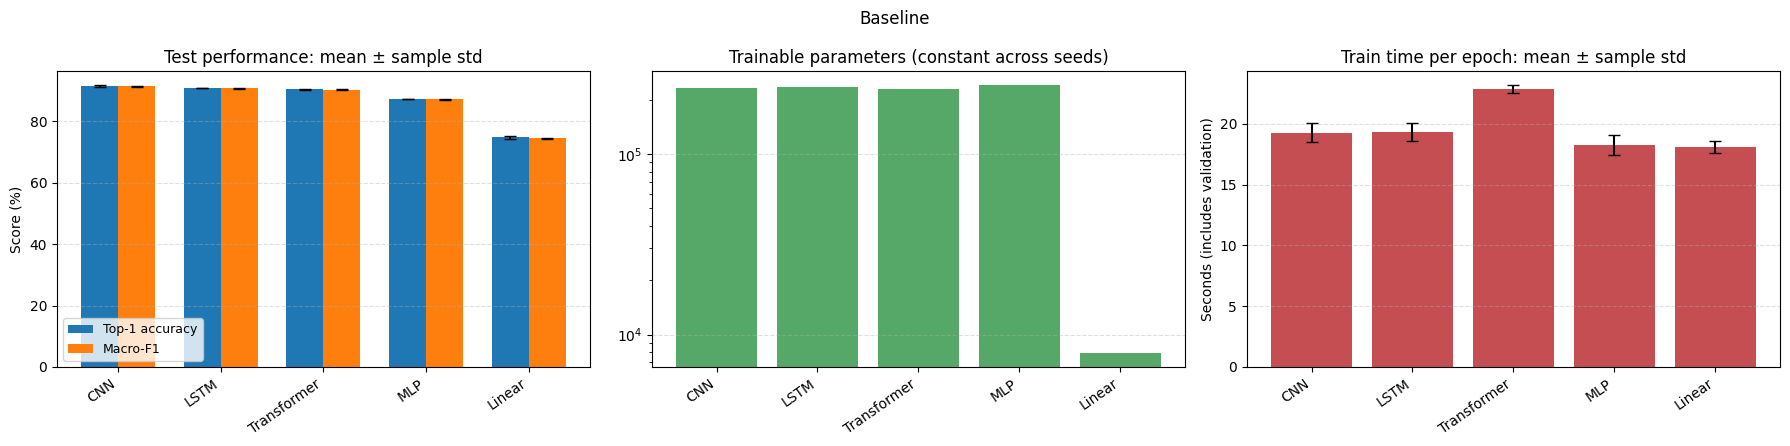

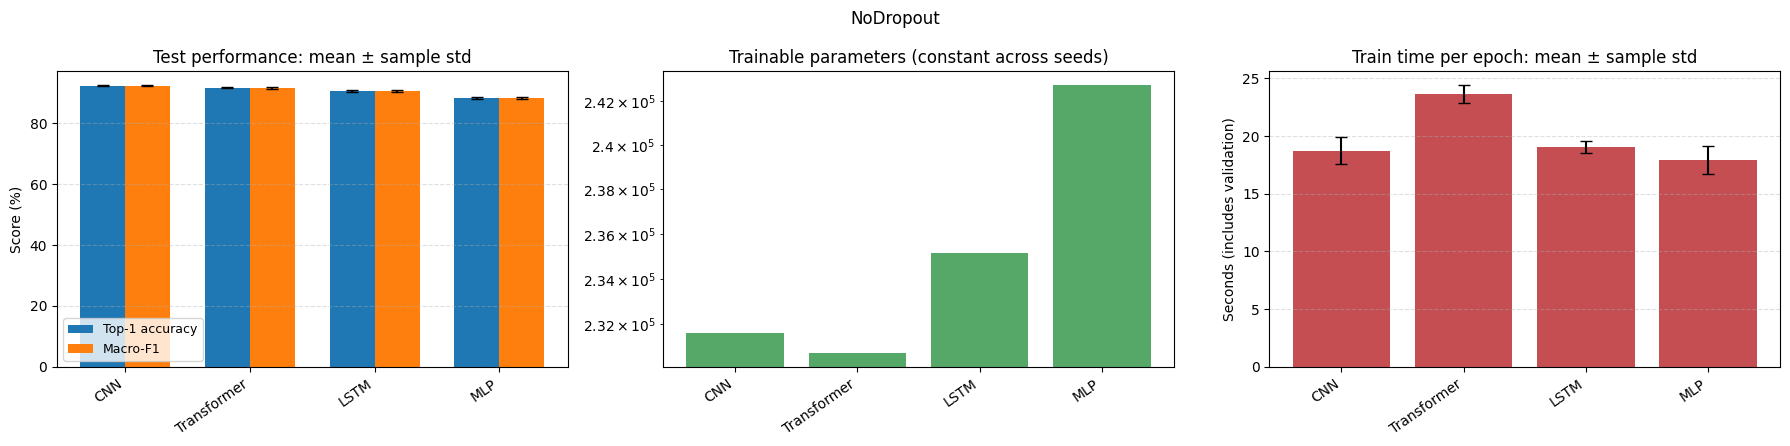

In [27]:
if not results_df.empty:
  for variant, group in results_df.groupby("variant", sort=False):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    x = np.arange(len(group))
    axes[0].bar(x - 0.18, 100 * group["test_accuracy_mean"], width=0.36,
          yerr=100 * group["test_accuracy_std"], capsize=4, label="Top-1 accuracy")
    axes[0].bar(x + 0.18, 100 * group["test_macro_f1_mean"], width=0.36,
          yerr=100 * group["test_macro_f1_std"], capsize=4, label="Macro-F1")
    axes[0].set_ylabel("Score (%)")
    axes[0].set_title("Test performance: mean ± sample std")
    axes[0].legend(fontsize=9)
    axes[1].bar(x, group["params"], color="#55A868")
    axes[1].set_title("Trainable parameters (constant across seeds)")
    axes[1].set_yscale("log")
    axes[2].bar(x, group["train_time_per_epoch_sec_mean"],
          yerr=group["train_time_per_epoch_sec_std"], capsize=4, color="#C44E52")
    axes[2].set_title("Train time per epoch: mean ± sample std")
    axes[2].set_ylabel("Seconds (includes validation)")
    for ax in axes:
      ax.set_xticks(x)
      ax.set_xticklabels(group["model"], rotation=35, ha="right")
      ax.grid(axis="y", linestyle="--", alpha=0.4)
    fig.suptitle(variant)
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, f"{variant}_mean_std_comparison.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
else:
  print("No complete multi-seed summary available.")


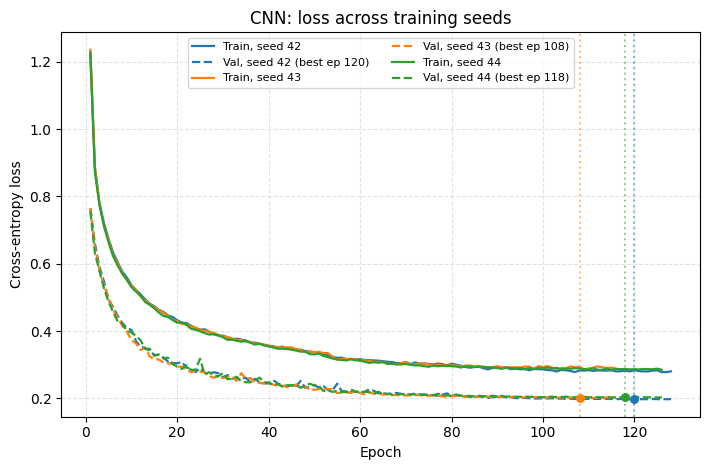

Saved: /content/fmnist_multiseed_42_43_44/Baseline_CNN_loss_all_seeds.png


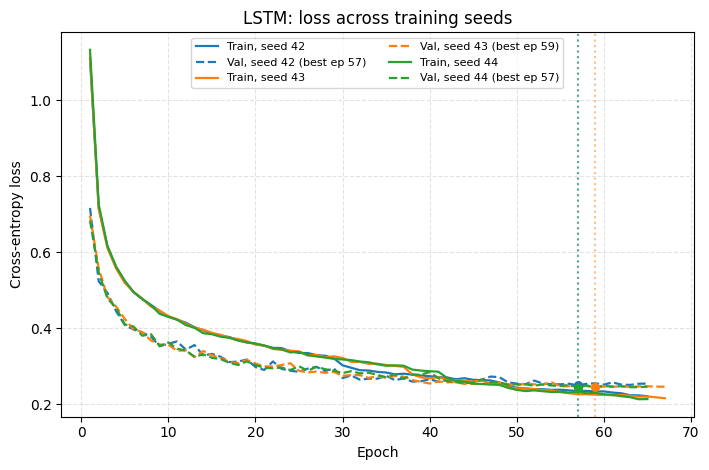

Saved: /content/fmnist_multiseed_42_43_44/Baseline_LSTM_loss_all_seeds.png


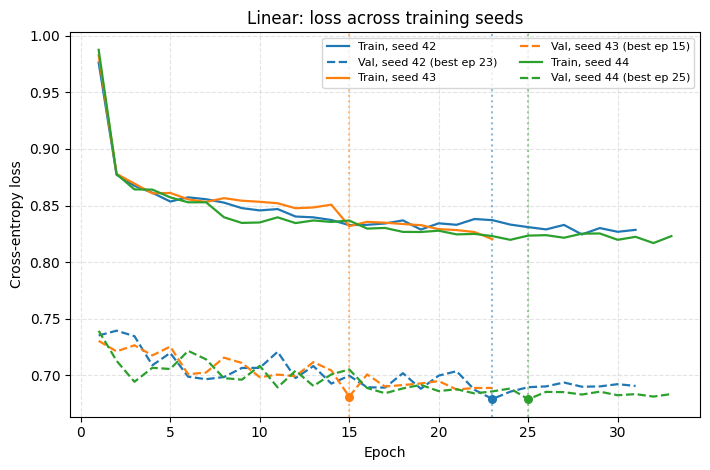

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Linear_loss_all_seeds.png


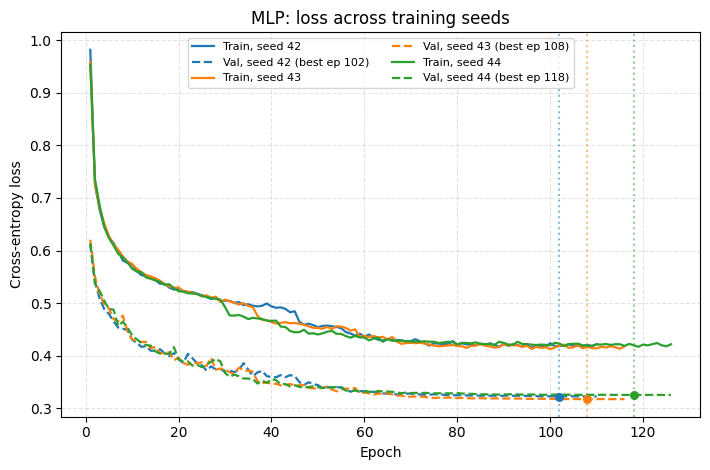

Saved: /content/fmnist_multiseed_42_43_44/Baseline_MLP_loss_all_seeds.png


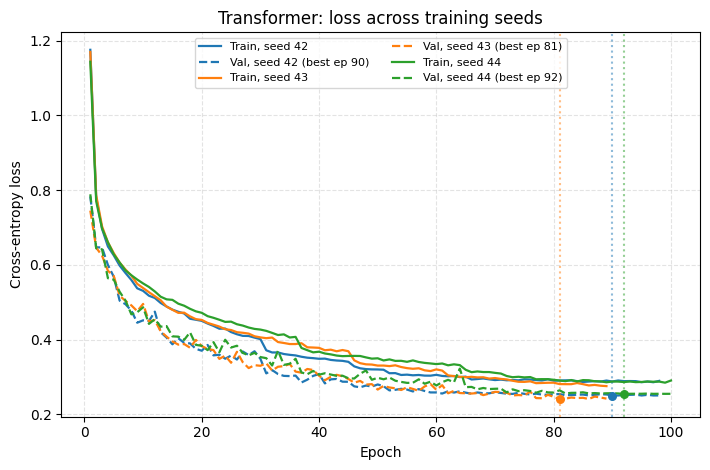

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Transformer_loss_all_seeds.png


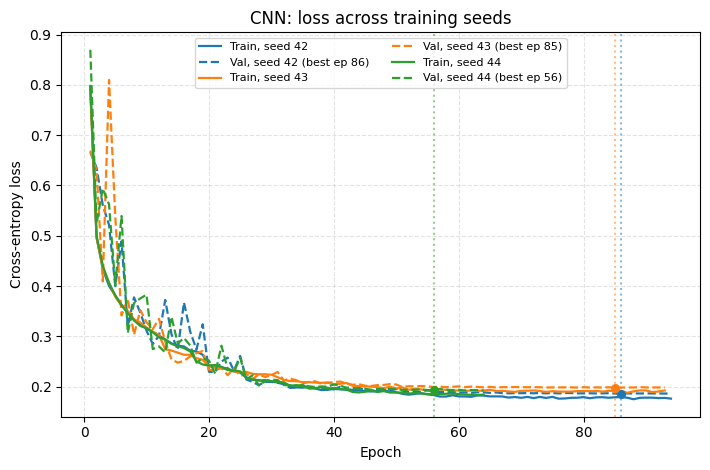

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_CNN_loss_all_seeds.png


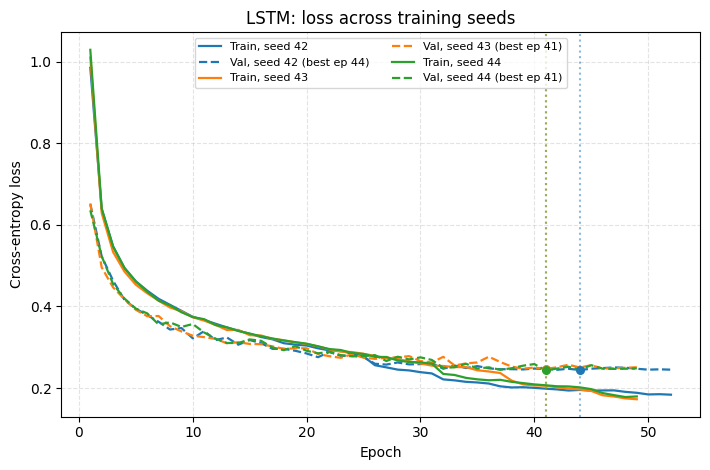

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_LSTM_loss_all_seeds.png


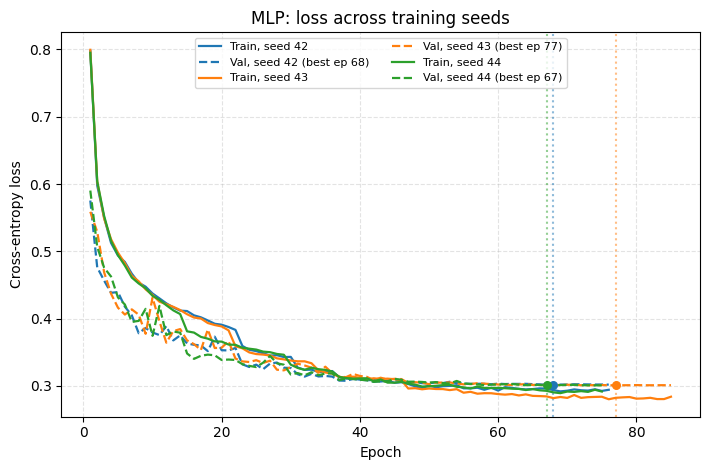

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_MLP_loss_all_seeds.png


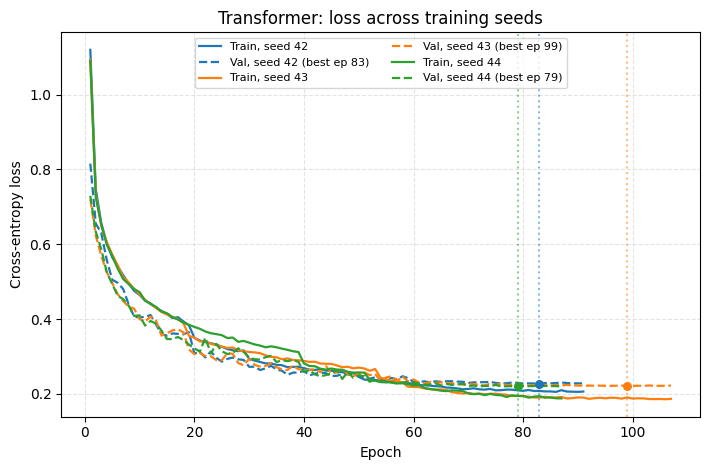

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_Transformer_loss_all_seeds.png


In [28]:
def plot_seed_curves(metric):
  if metric not in {"loss", "acc"}:
    raise ValueError(metric)
  groups = sorted({(variant, name) for variant, name, seed in evaluated_runs})
  for variant, name in groups:
    records = [(seed, evaluated_runs[(variant, name, seed)]) for seed in TRAIN_SEEDS
          if (variant, name, seed) in evaluated_runs]
    if REQUIRE_ALL_SEEDS and len(records) != len(TRAIN_SEEDS):
      continue
    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    for index, (seed, details) in enumerate(records):
      history = details["history"]
      color = plt.get_cmap("tab10")(index)
      scale = 100 if metric == "acc" else 1
      train = scale * np.asarray(history["train_" + metric])
      val = scale * np.asarray(history["val_" + metric])
      best_epoch = int(np.argmin(history["val_loss"])) + 1
      ax.plot(np.arange(1, len(train) + 1), train, color=color,
          linewidth=1.6, label=f"Train, seed {seed}")
      ax.plot(np.arange(1, len(val) + 1), val, color=color, linestyle="--",
          linewidth=1.6, label=f"Val, seed {seed} (best ep {best_epoch})")
      ax.axvline(best_epoch, color=color, linestyle=":", alpha=0.5)
      ax.scatter(best_epoch, val[best_epoch - 1], color=color, s=30, zorder=5)
    if metric == "acc":
      ax.set_title(f"{name}: Accuracy across training seeds")
    else:
      ax.set_title(f"{name}: {metric} across training seeds")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Top-1 accuracy (%)" if metric == "acc" else "Cross-entropy loss")
    if metric == "acc":
      ax.set_ylim(0, 100)
    ax.legend(fontsize=8, ncol=2)
    ax.grid(True, linestyle="--", alpha=0.35)
    fig.tight_layout()
    path = os.path.join(RUNTIME_FIG_DIR, f"{variant}_{name}_{metric}_all_seeds.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved:", path)


plot_seed_curves("loss")


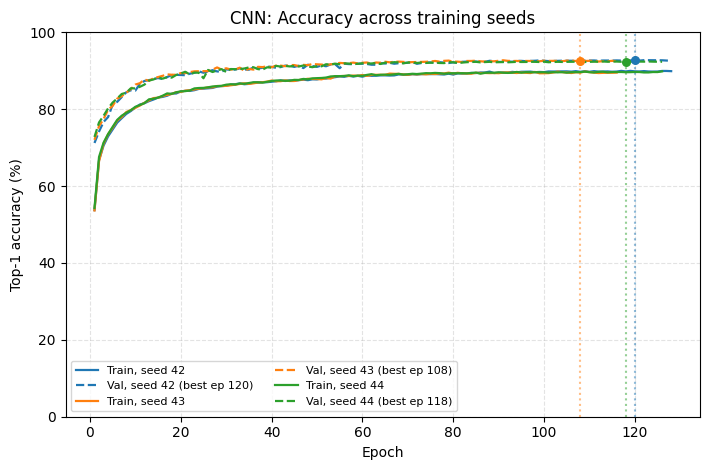

Saved: /content/fmnist_multiseed_42_43_44/Baseline_CNN_acc_all_seeds.png


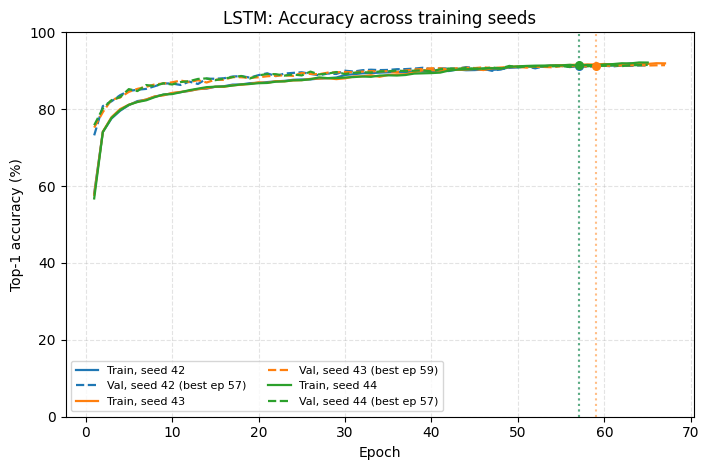

Saved: /content/fmnist_multiseed_42_43_44/Baseline_LSTM_acc_all_seeds.png


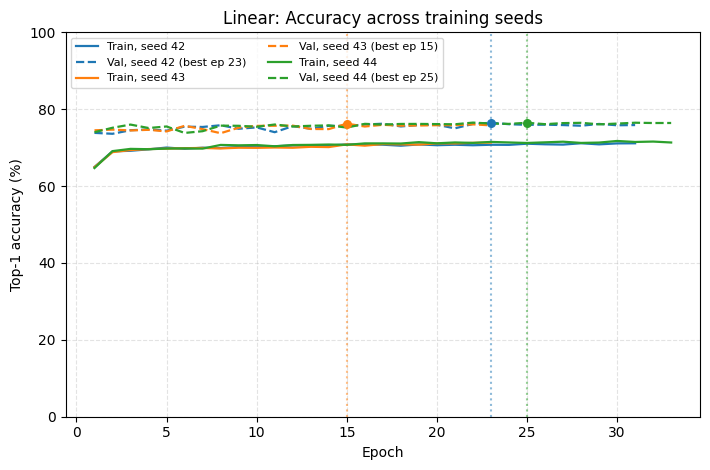

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Linear_acc_all_seeds.png


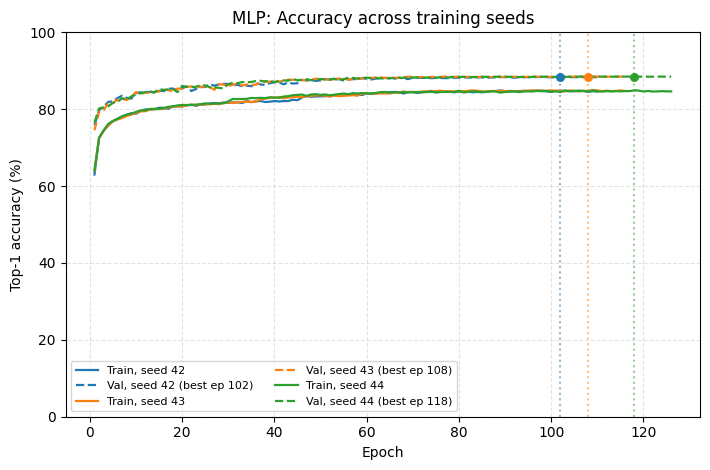

Saved: /content/fmnist_multiseed_42_43_44/Baseline_MLP_acc_all_seeds.png


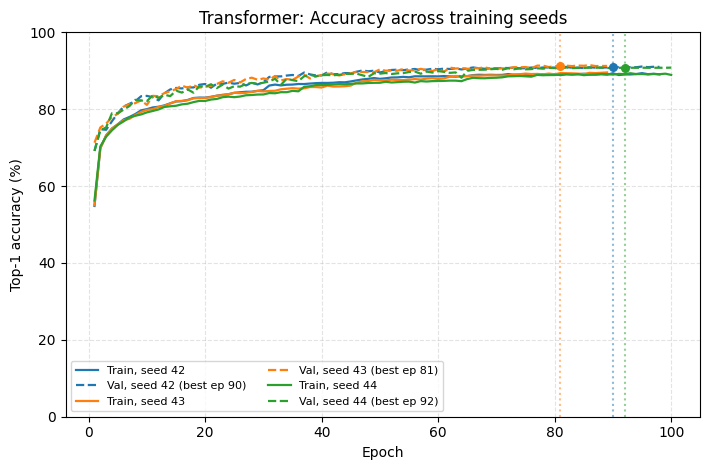

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Transformer_acc_all_seeds.png


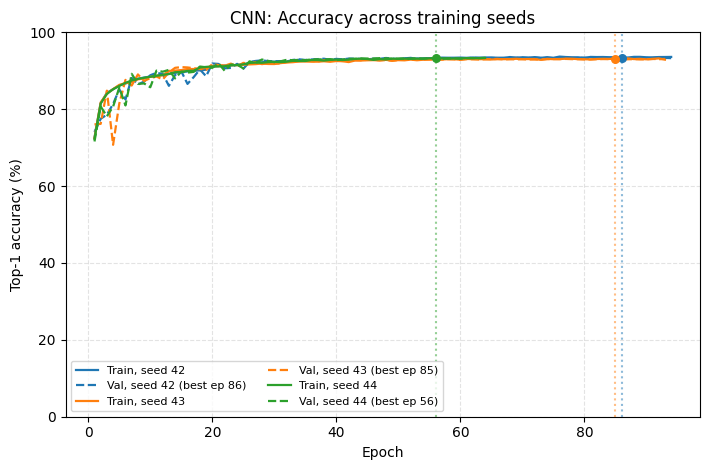

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_CNN_acc_all_seeds.png


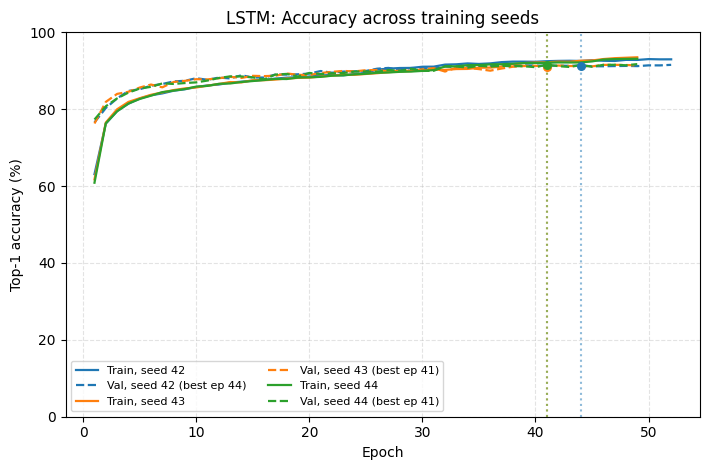

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_LSTM_acc_all_seeds.png


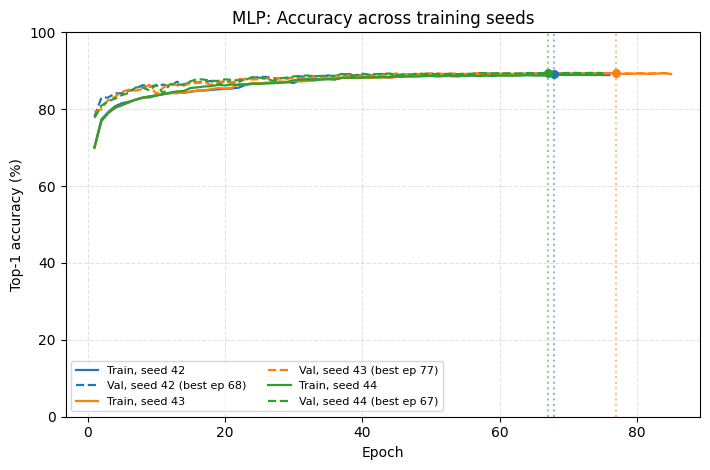

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_MLP_acc_all_seeds.png


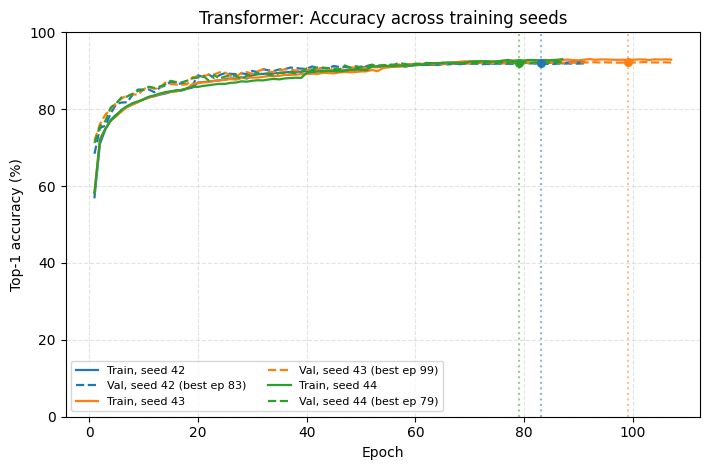

Saved: /content/fmnist_multiseed_42_43_44/NoDropout_Transformer_acc_all_seeds.png


In [29]:
plot_seed_curves("acc")


## 15. Confusion matrices


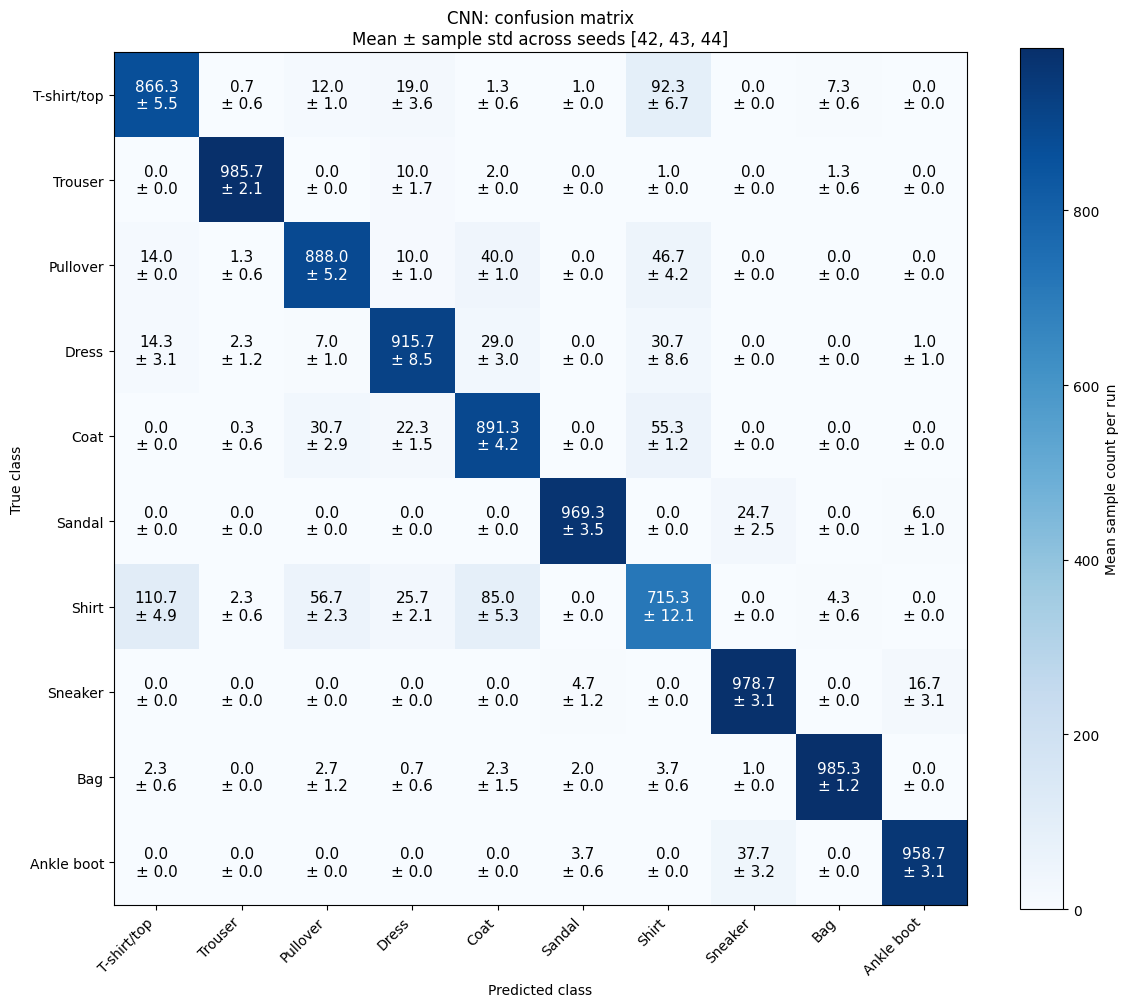

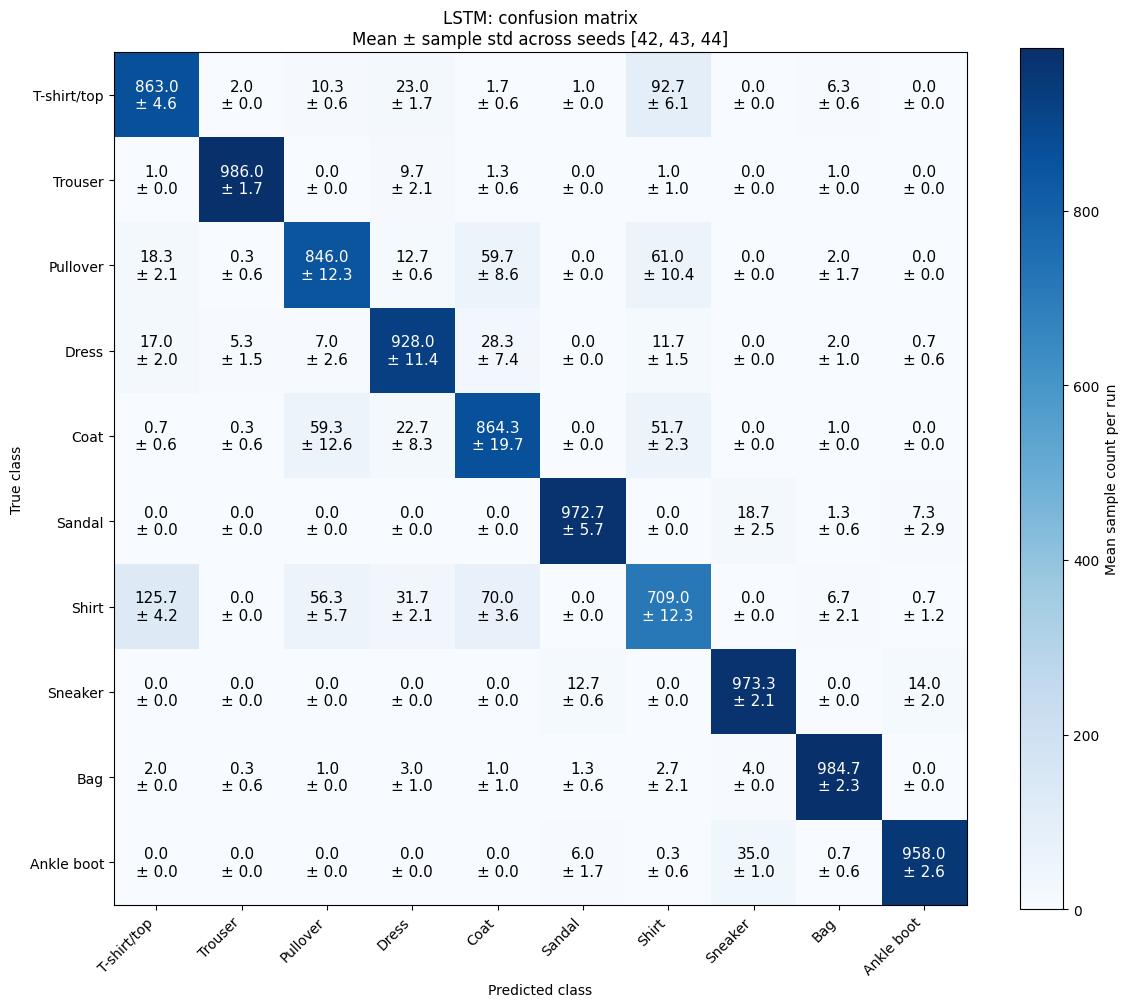

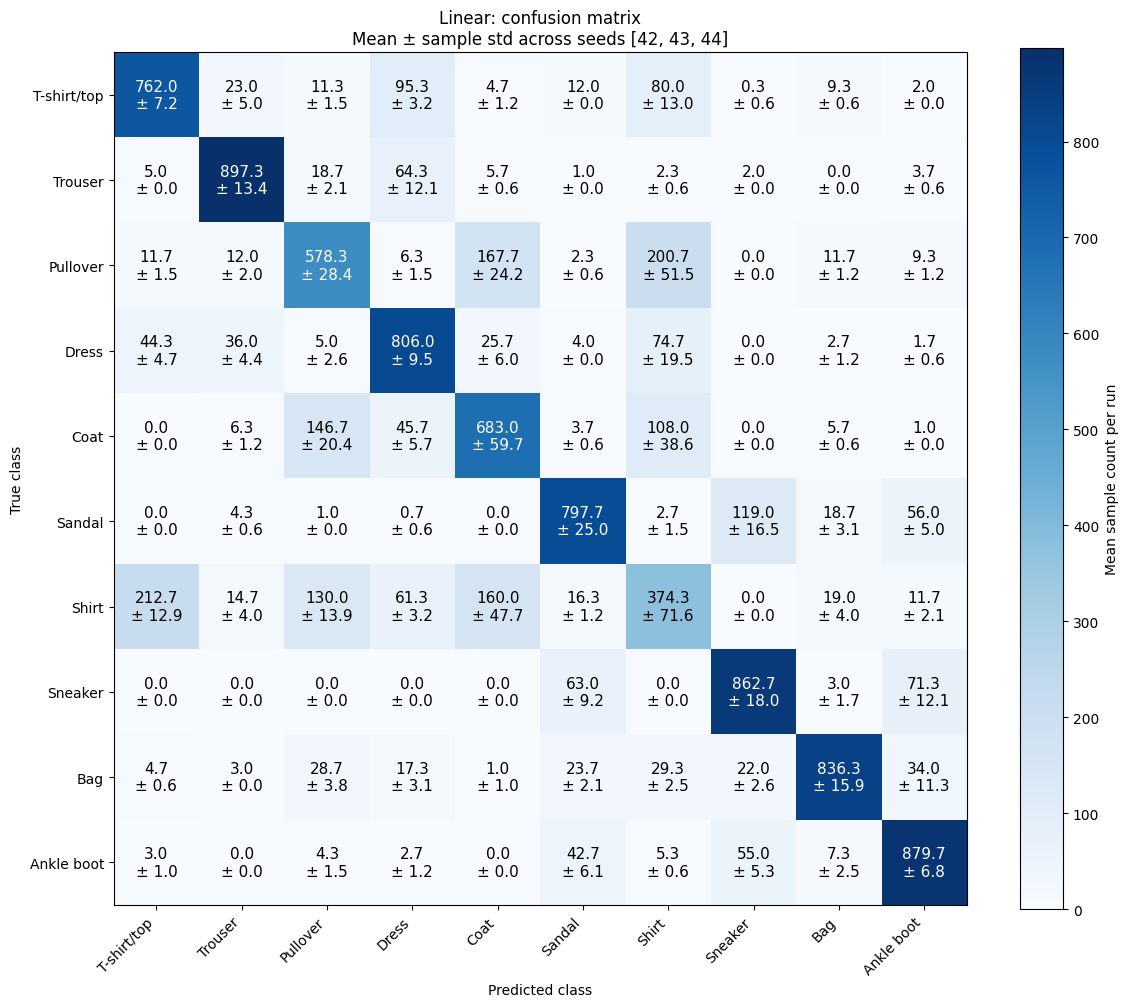

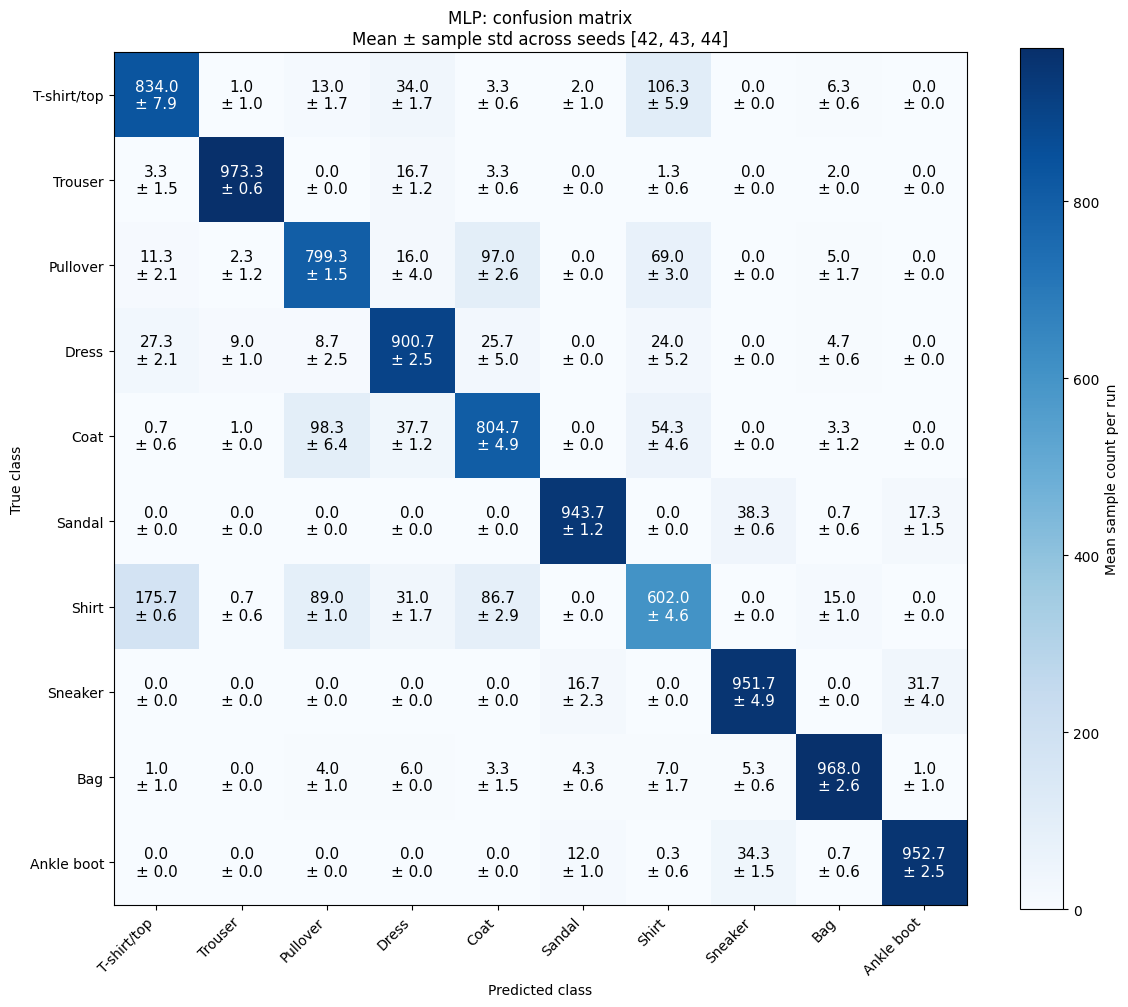

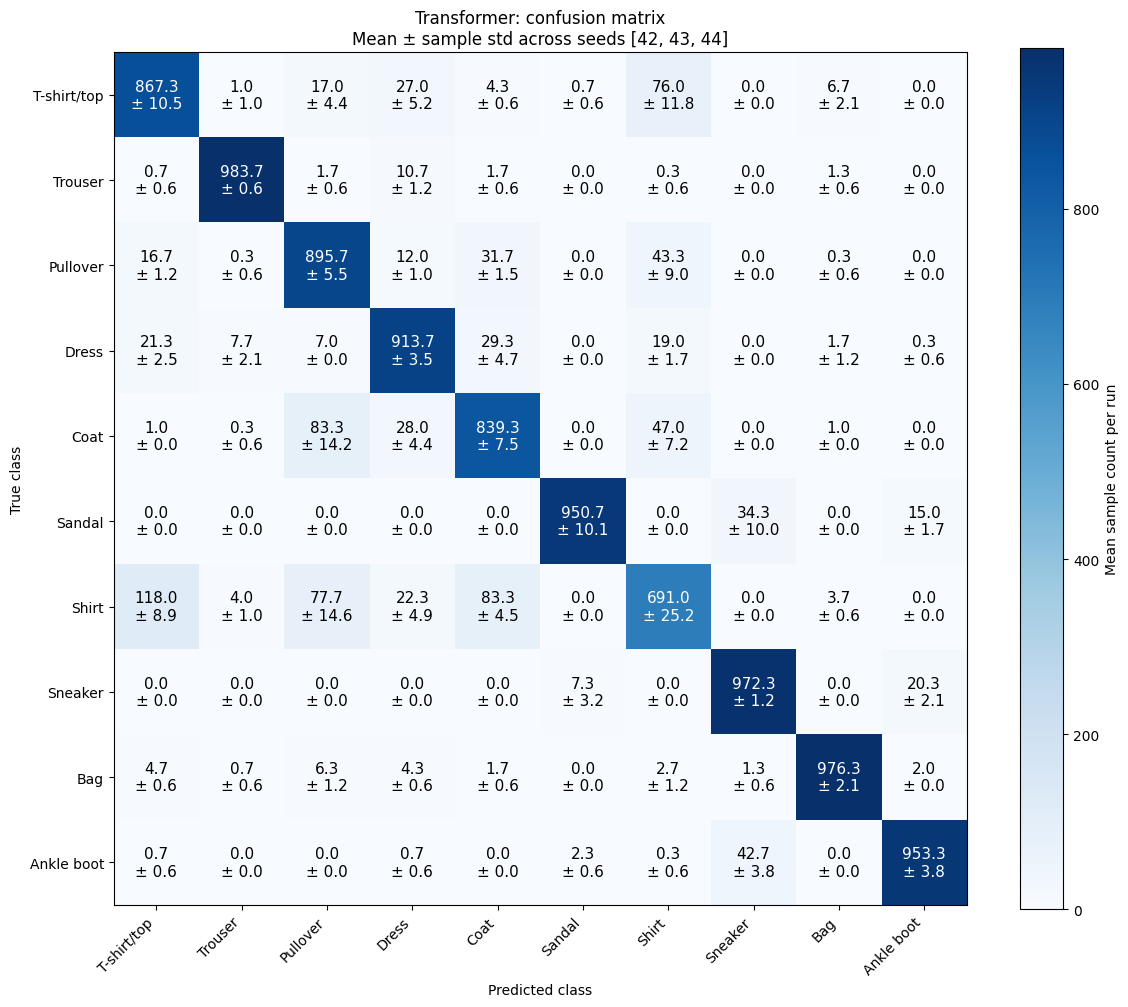

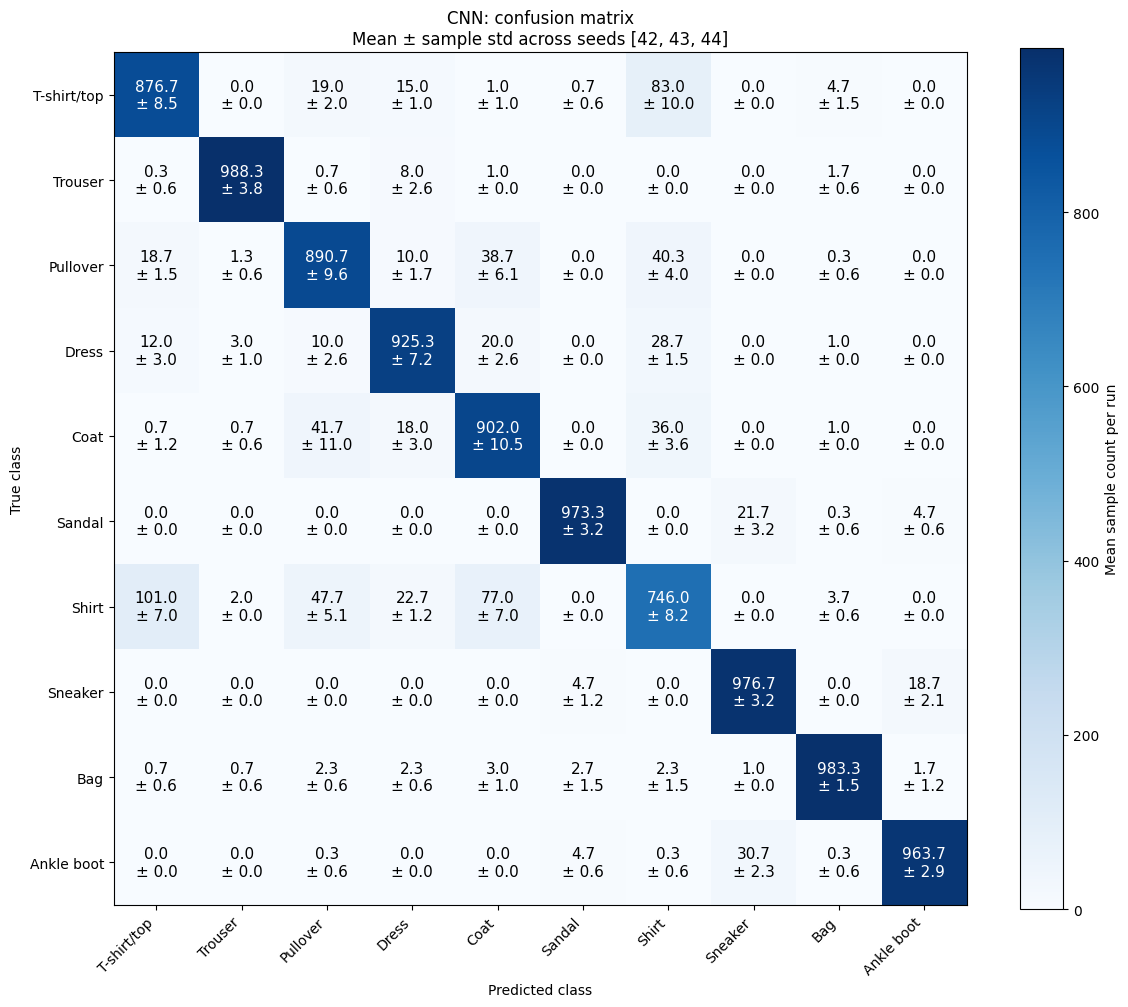

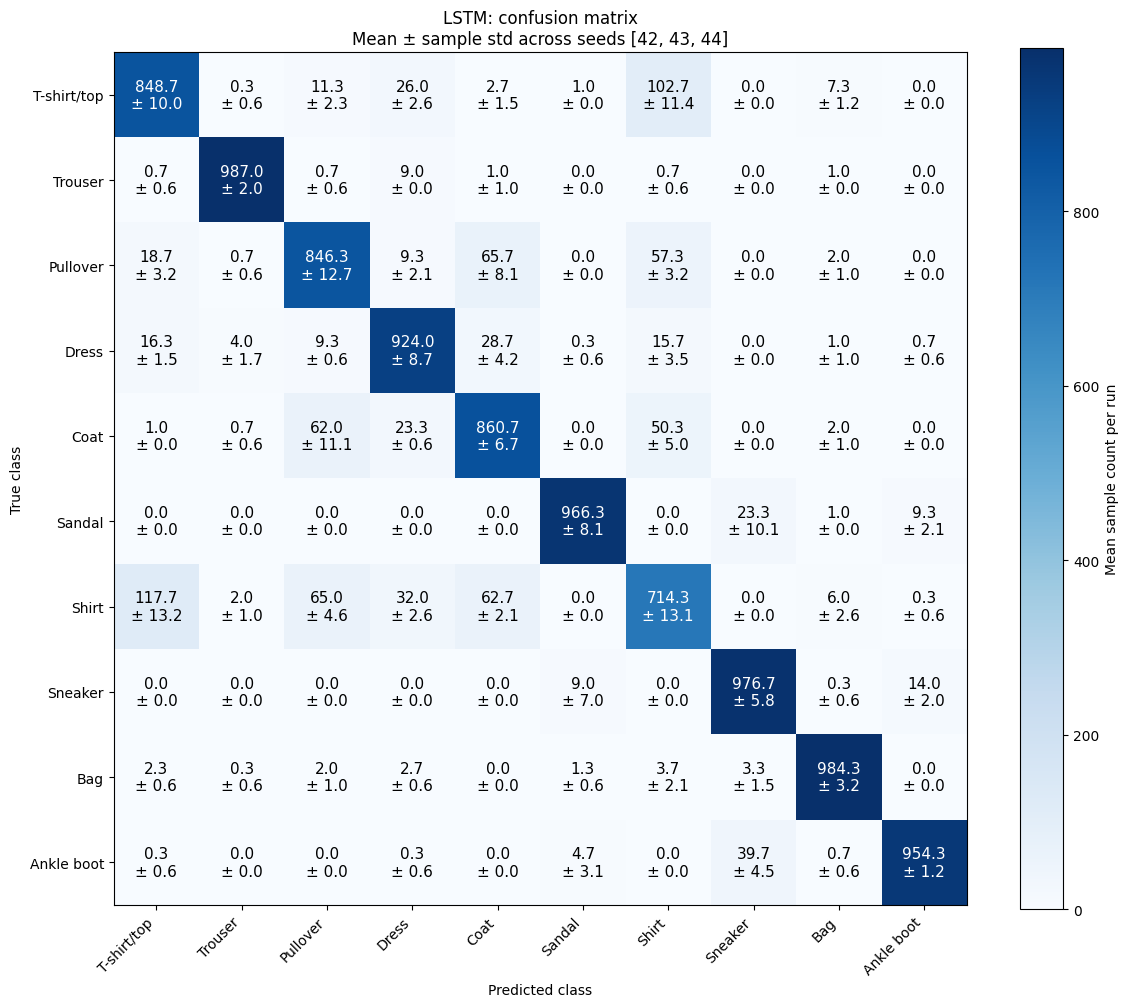

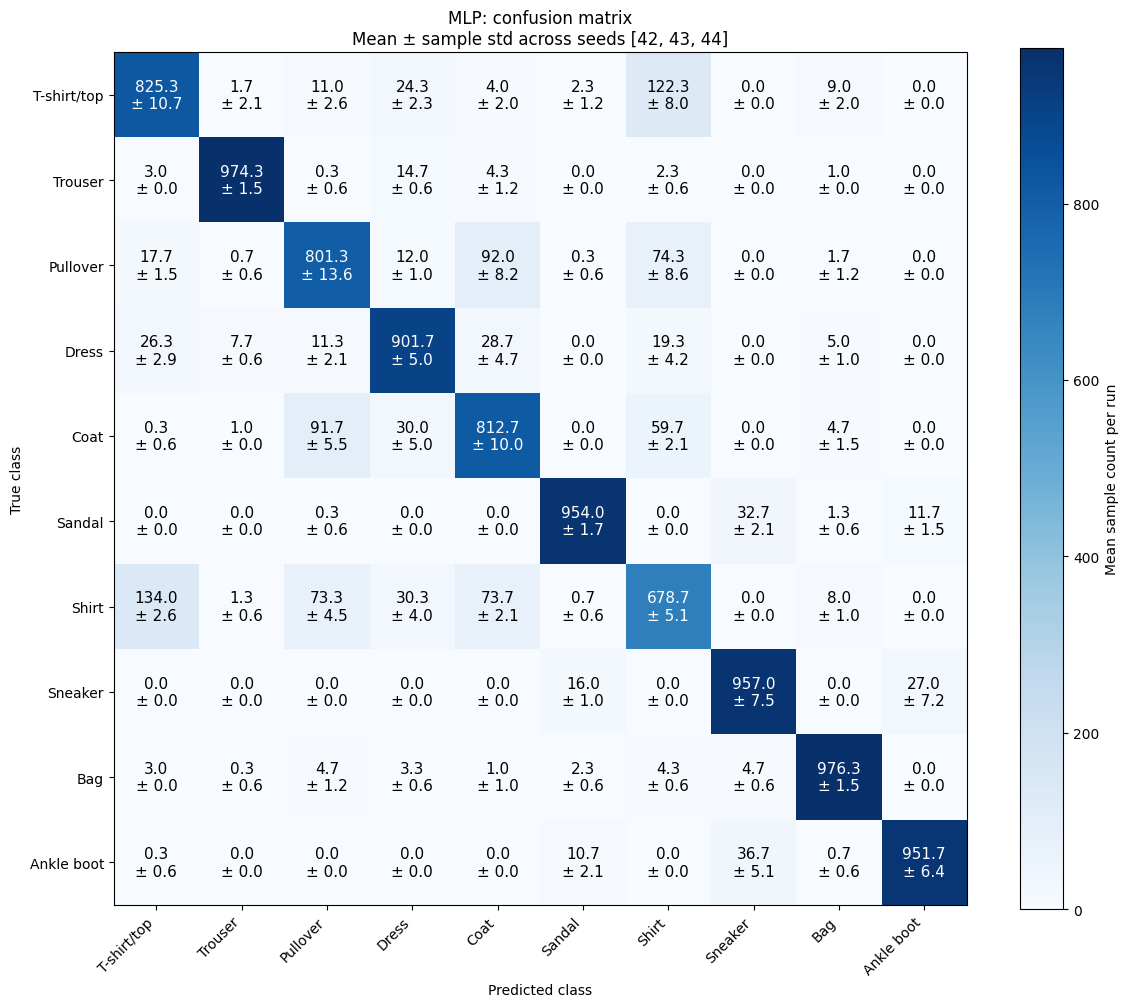

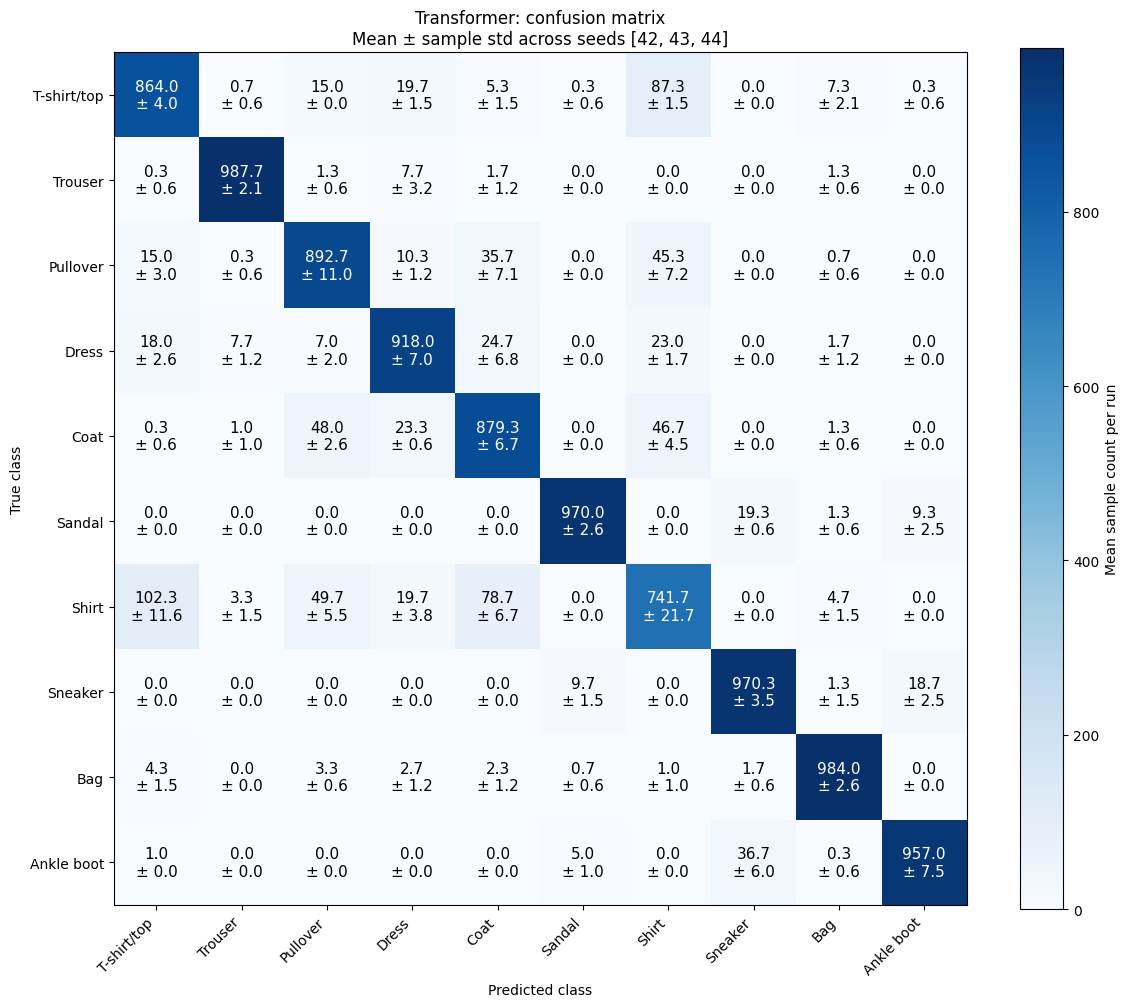

In [30]:
CM_DIR = os.path.join(RUNTIME_FIG_DIR, "confusion_matrices")
os.makedirs(CM_DIR, exist_ok=True)
for variant, name in sorted({(v, n) for v, n, s in evaluated_runs}):
  matrices = []
  seeds_used = []
  for seed in TRAIN_SEEDS:
    record = evaluated_runs.get((variant, name, seed))
    if record is None:
      continue

    cm = confusion_matrix(
      record["y_true"],
      record["y_pred"],
      labels=range(NUM_CLASSES)
    )
    matrices.append(cm)
    seeds_used.append(seed)
    pd.DataFrame(
      cm, index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(
      os.path.join(
        RESULTS_DIR,
        f"{variant}_{name}_seed{seed}_confusion_counts.csv"
      )
    )
  if not matrices or (
    REQUIRE_ALL_SEEDS and len(matrices) != len(TRAIN_SEEDS)
  ):
    continue

  # Mean và sample standard deviation theo từng ô
  stacked_cm = np.stack(matrices).astype(float)
  mean_cm = stacked_cm.mean(axis=0)

  if len(matrices) > 1:
    std_cm = stacked_cm.std(axis=0, ddof=1)
  else:
    # Không thể tính sample std với chỉ một run
    std_cm = np.full_like(mean_cm, np.nan)

  # Lưu mean và std thành hai CSV riêng
  for statistic, values in (("mean", mean_cm), ("std", std_cm)):
    pd.DataFrame(
      values, index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(
      os.path.join(
        RESULTS_DIR,
        f"{variant}_{name}_{statistic}_confusion_counts.csv"
      )
    )

  fig, ax = plt.subplots(figsize=(12, 10))

  im = ax.imshow(mean_cm, cmap="Blues", vmin=0)
  fig.colorbar(im, ax=ax, label="Mean sample count per run")

  for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
      std_text = (
        f"{std_cm[i, j]:.1f}"
        if np.isfinite(std_cm[i, j])
        else "N/A"
      )

      ax.text(
        j, i,
        f"{mean_cm[i, j]:.1f}\n± {std_text}",
        ha="center",
        va="center",
        fontsize=11,
        linespacing=1.2,
        color=(
          "white"
          if im.norm(mean_cm[i, j]) > 0.5
          else "black"
        )
      )

  ax.set_xticks(range(NUM_CLASSES))
  ax.set_yticks(range(NUM_CLASSES))
  ax.set_xticklabels(
    CLASS_NAMES, rotation=45, ha="right", fontsize=10
  )
  ax.set_yticklabels(CLASS_NAMES, fontsize=10)

  ax.set_xlabel("Predicted class")
  ax.set_ylabel("True class")
  ax.set_title(
    f"{name}: confusion matrix\n"
    f"Mean ± sample std across seeds {seeds_used}",
    fontsize=12
  )

  fig.tight_layout()
  fig.savefig(
    os.path.join(
      CM_DIR,
      f"{variant}_{name}_mean_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
  )
  plt.show()
  plt.close(fig)

## 16. Qualitative results for a predetermined seed

Use VIS_MODEL / VIS_VARIANT / VIS_SEED from the configuration cell. This seed is
specified before inspecting its test score. Correct, difficult-but-correct candidates
(smallest top-two softmax gaps), and failures are shown separately. Softmax scores
are not calibrated probabilities; visually inspect candidates before calling them difficult.



Qualitative results: Linear, seed 42


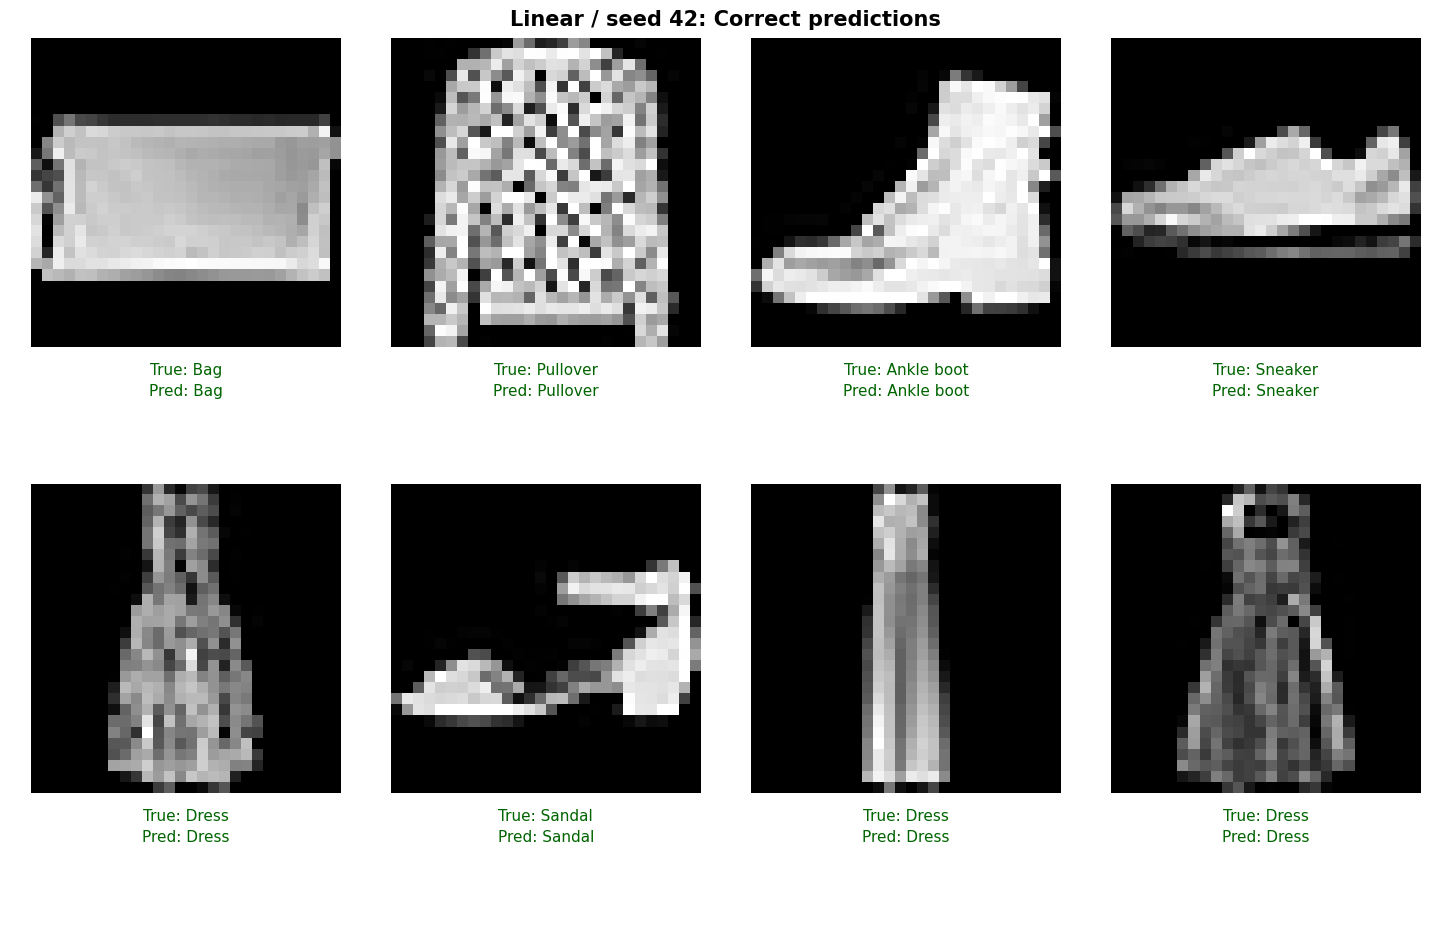

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Linear_seed42_Correct.png


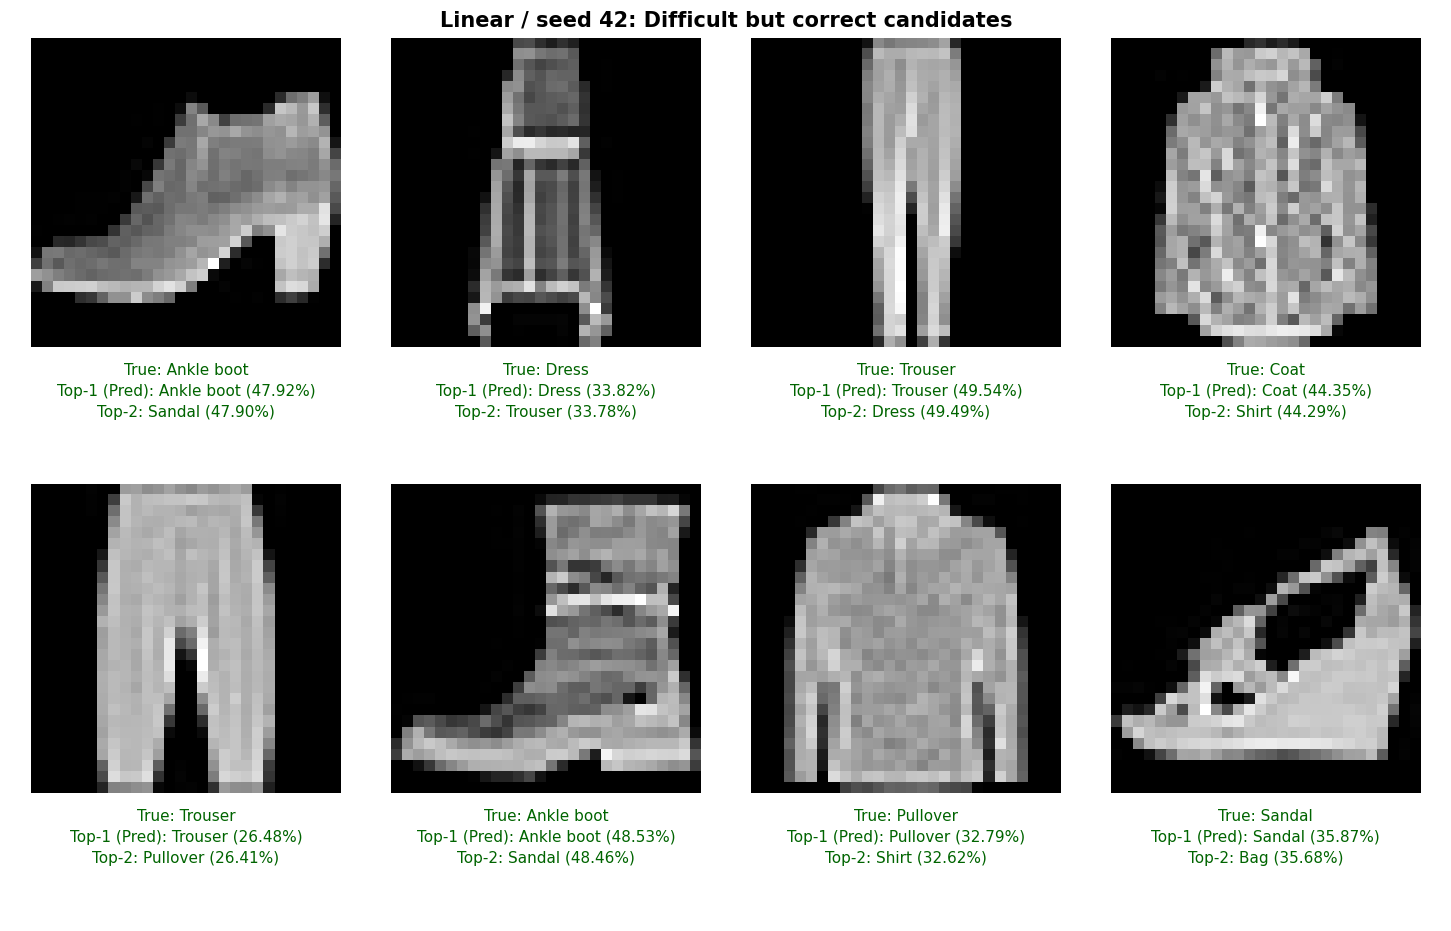

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Linear_seed42_Difficult_correct_candidates.png


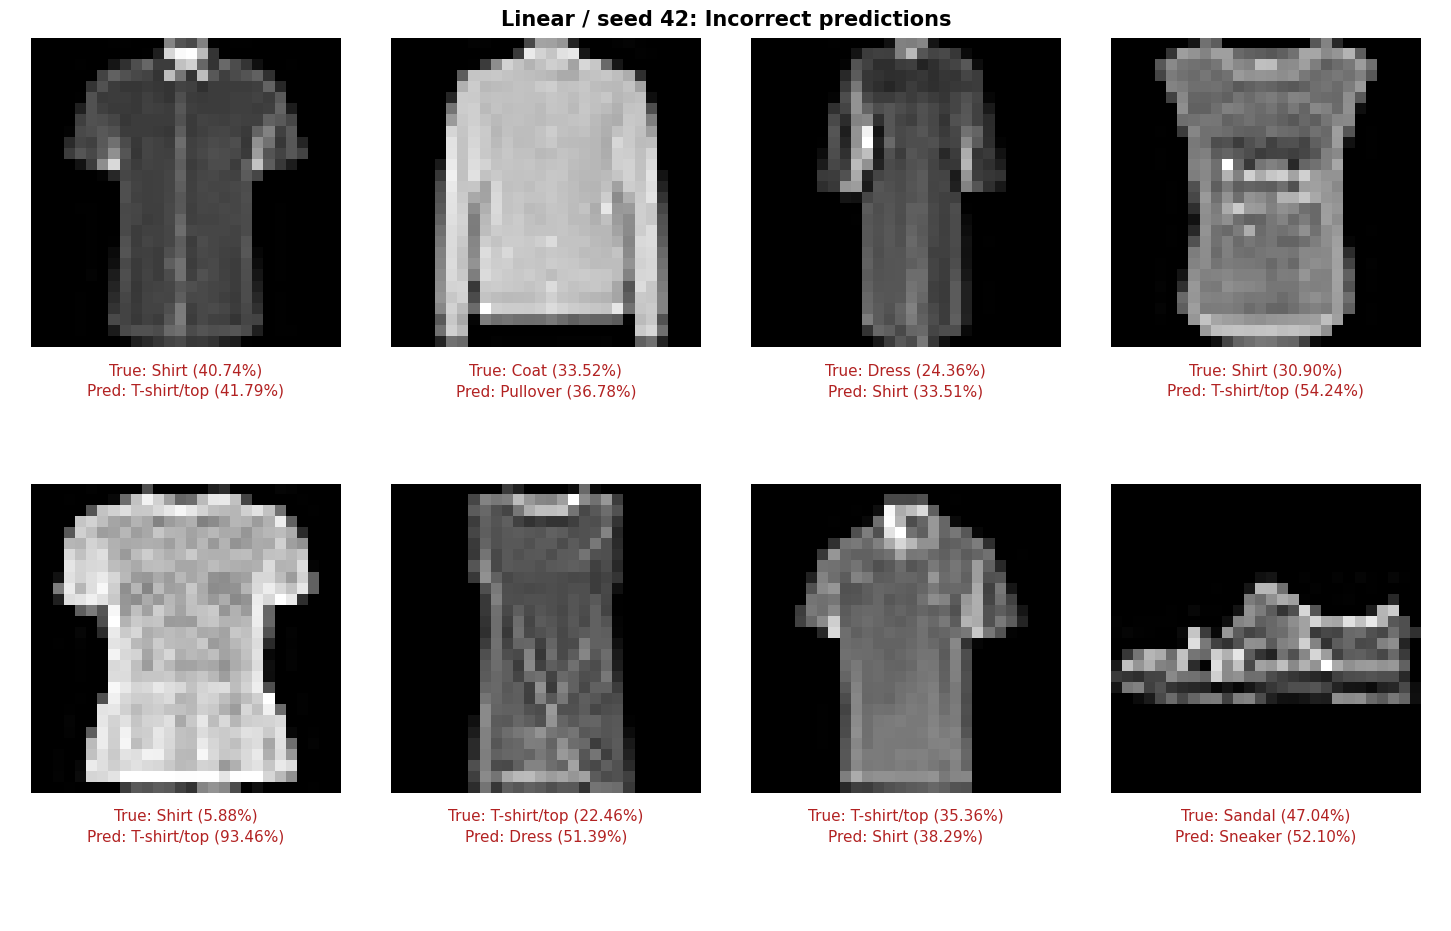

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Linear_seed42_Failures.png

Qualitative results: MLP, seed 42


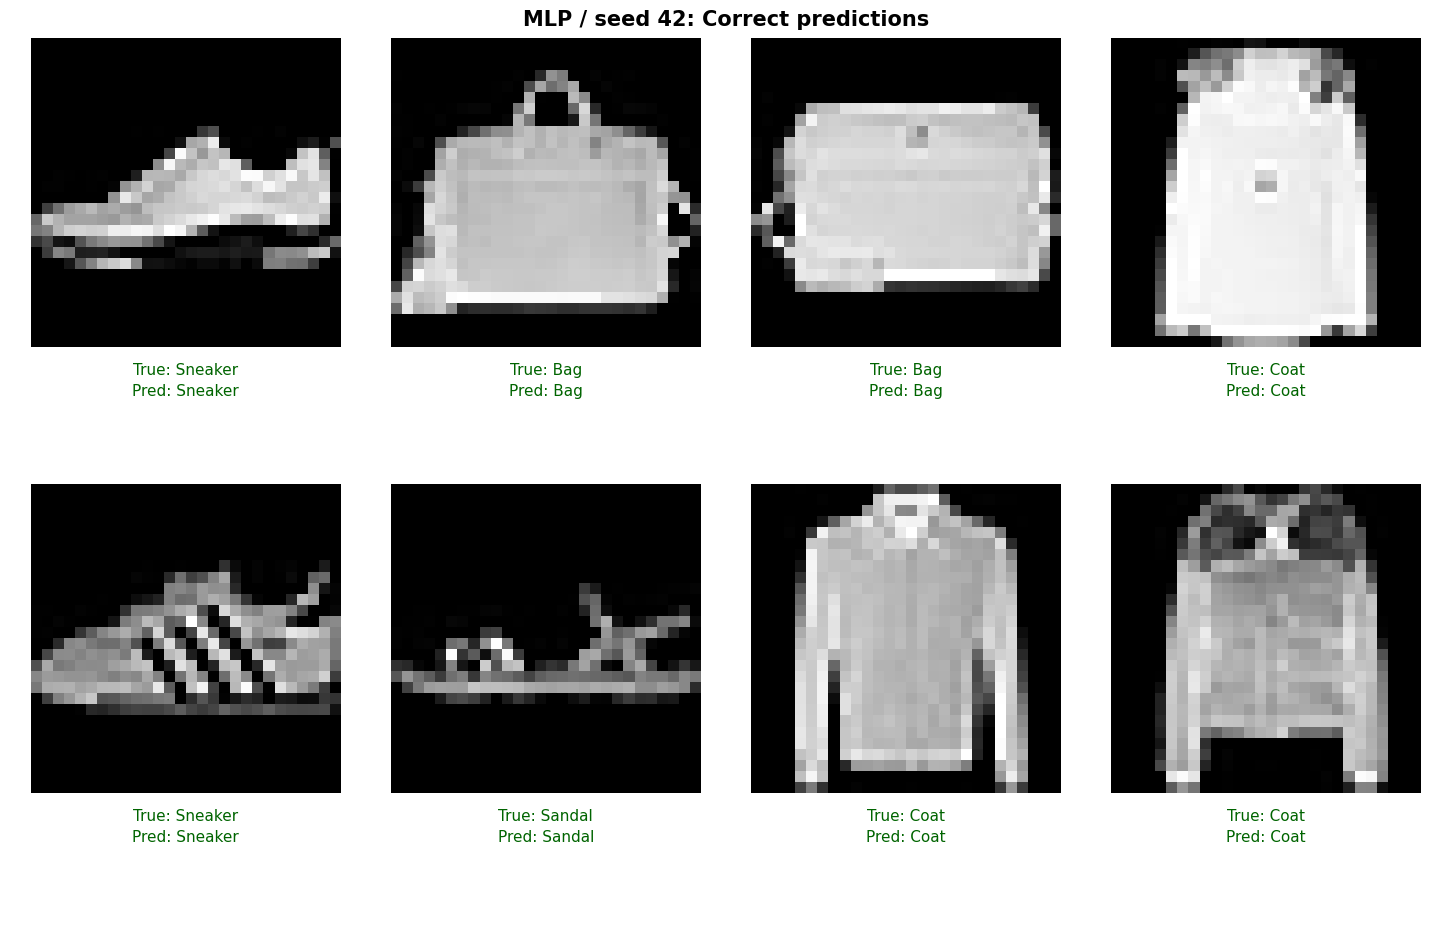

Saved: /content/fmnist_multiseed_42_43_44/Baseline_MLP_seed42_Correct.png


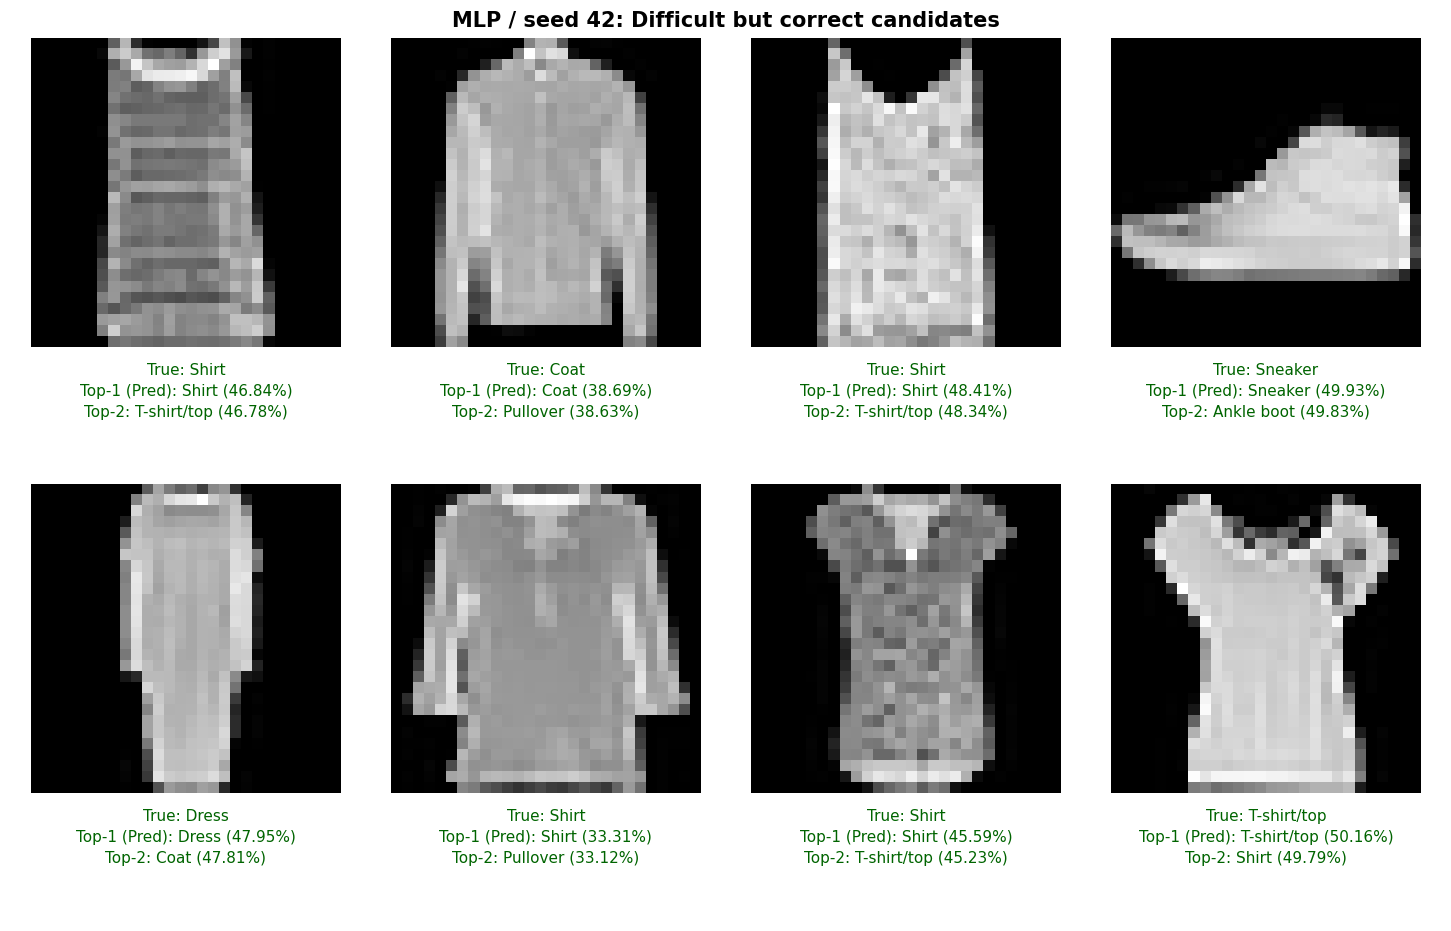

Saved: /content/fmnist_multiseed_42_43_44/Baseline_MLP_seed42_Difficult_correct_candidates.png


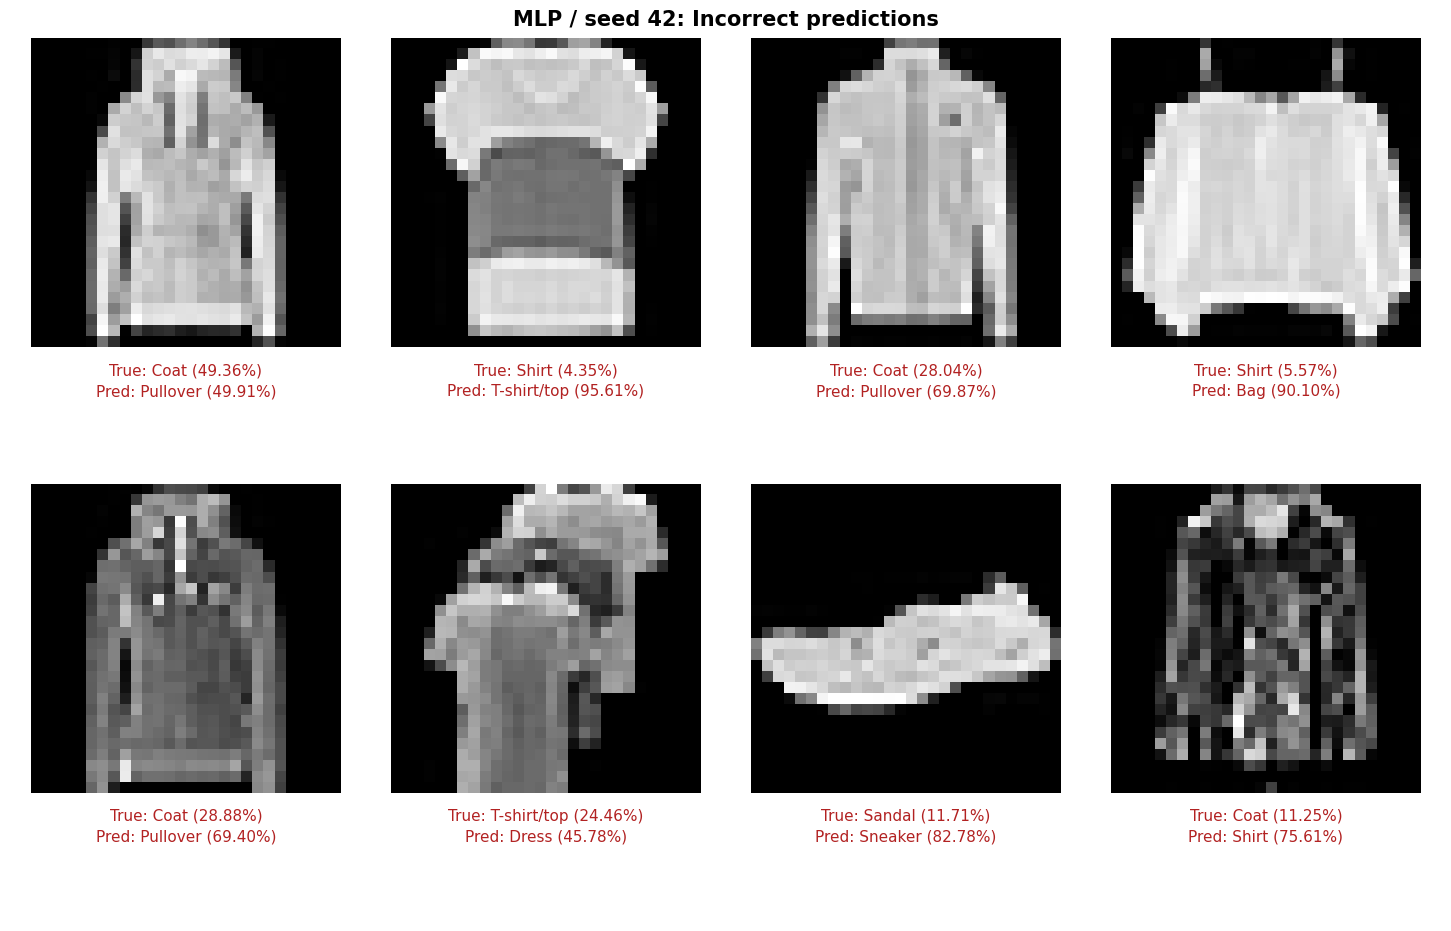

Saved: /content/fmnist_multiseed_42_43_44/Baseline_MLP_seed42_Failures.png

Qualitative results: CNN, seed 42


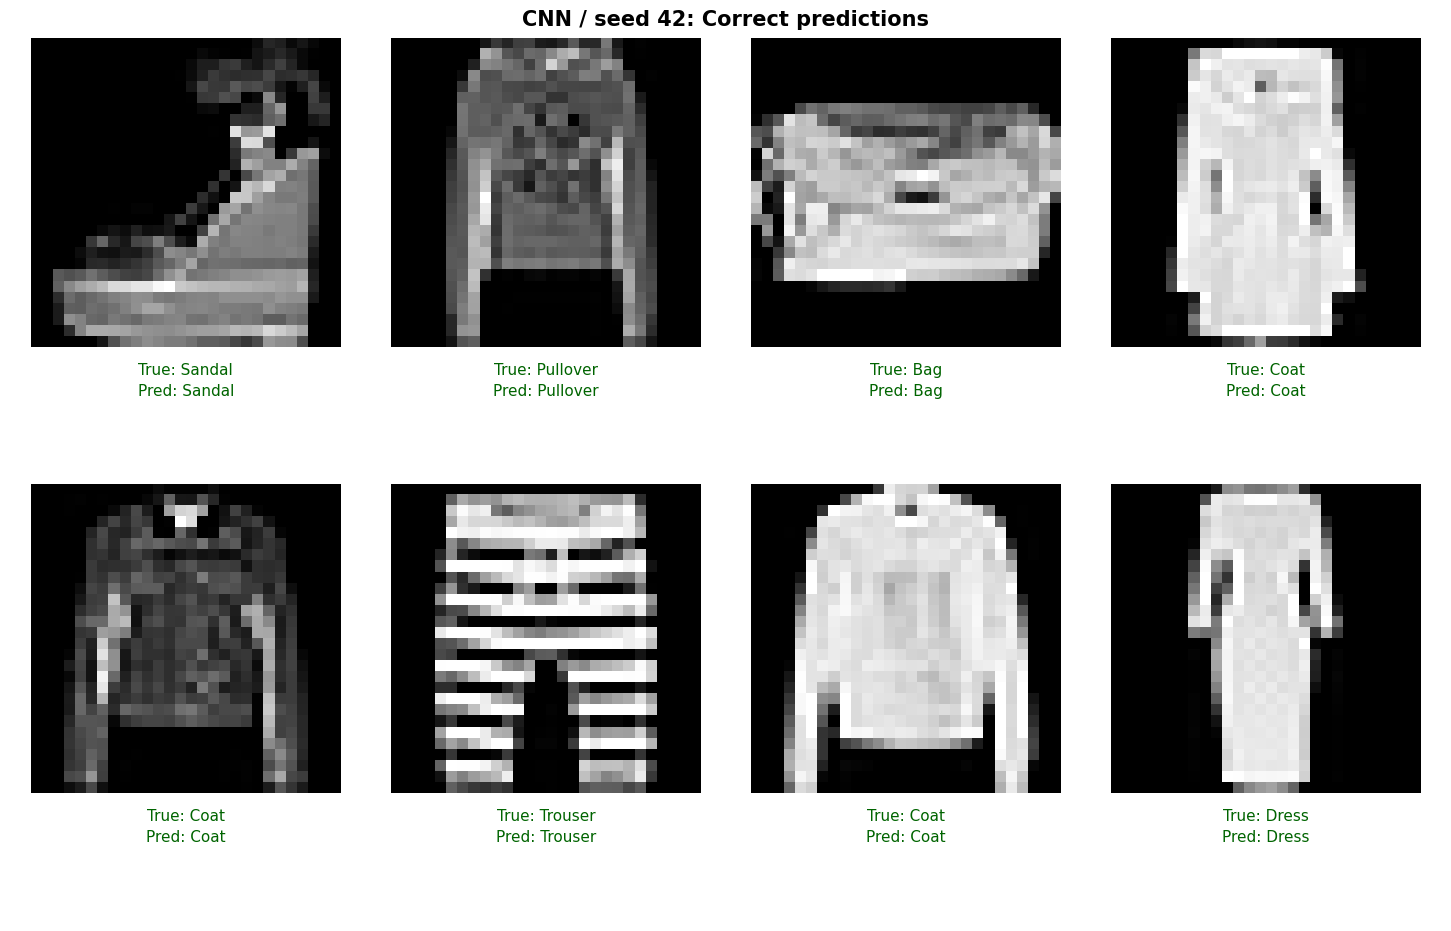

Saved: /content/fmnist_multiseed_42_43_44/Baseline_CNN_seed42_Correct.png


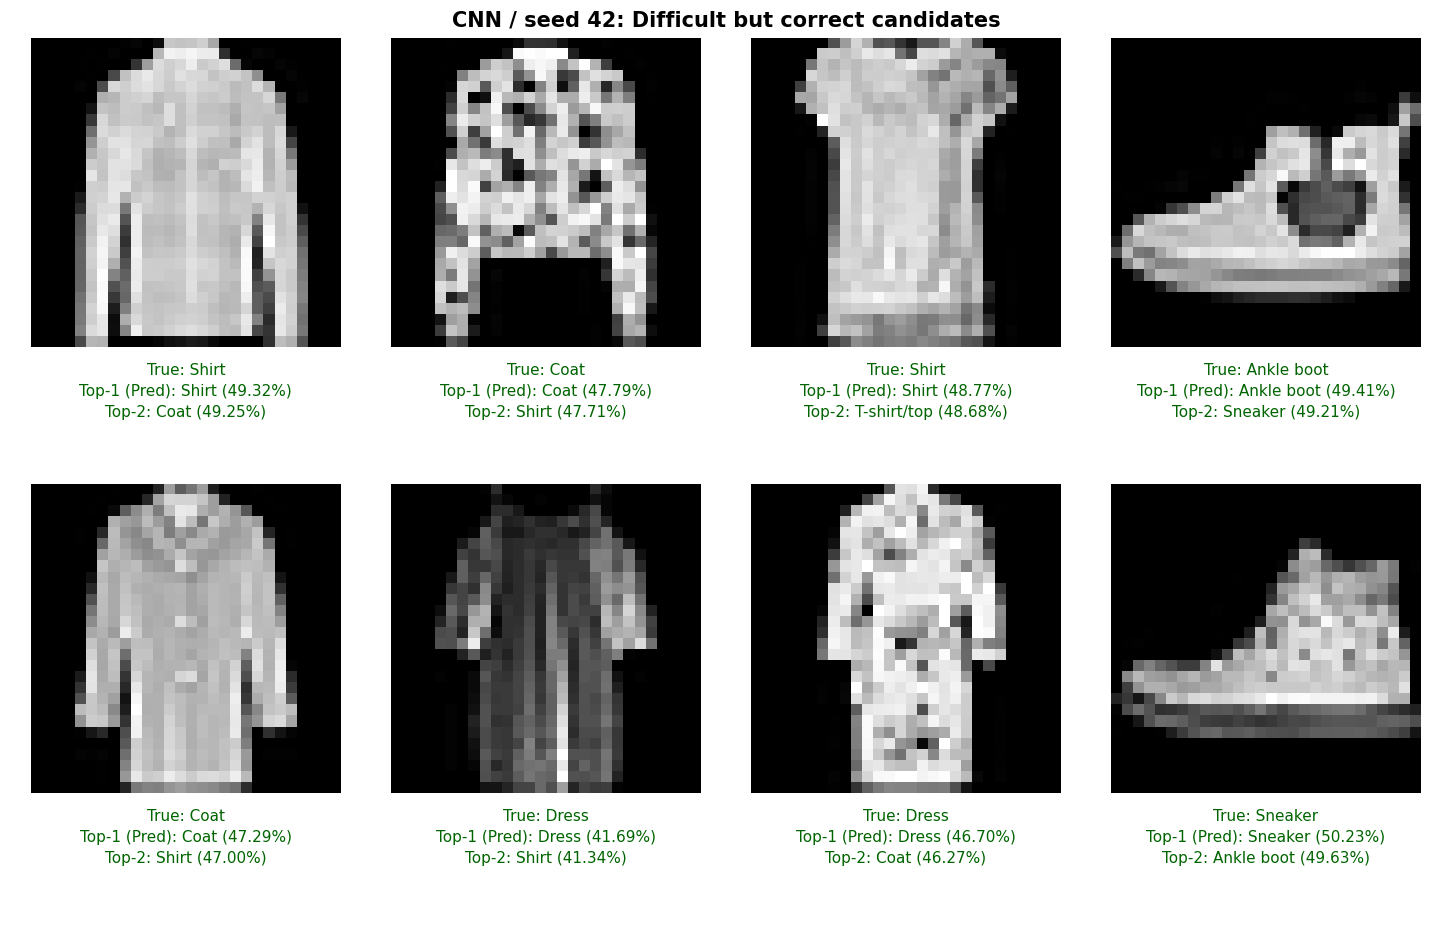

Saved: /content/fmnist_multiseed_42_43_44/Baseline_CNN_seed42_Difficult_correct_candidates.png


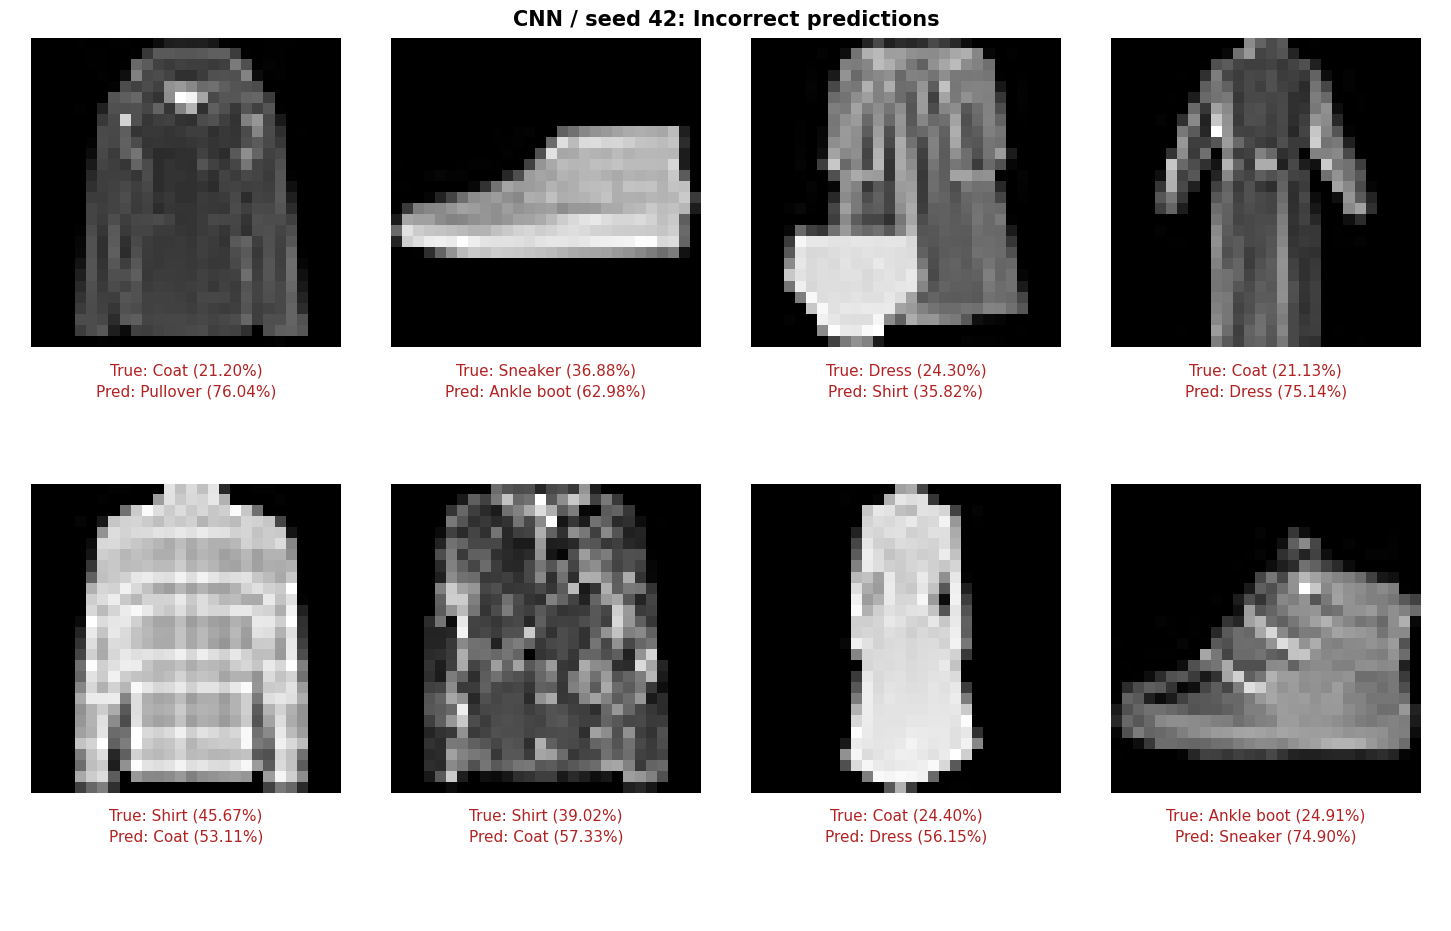

Saved: /content/fmnist_multiseed_42_43_44/Baseline_CNN_seed42_Failures.png

Qualitative results: LSTM, seed 42


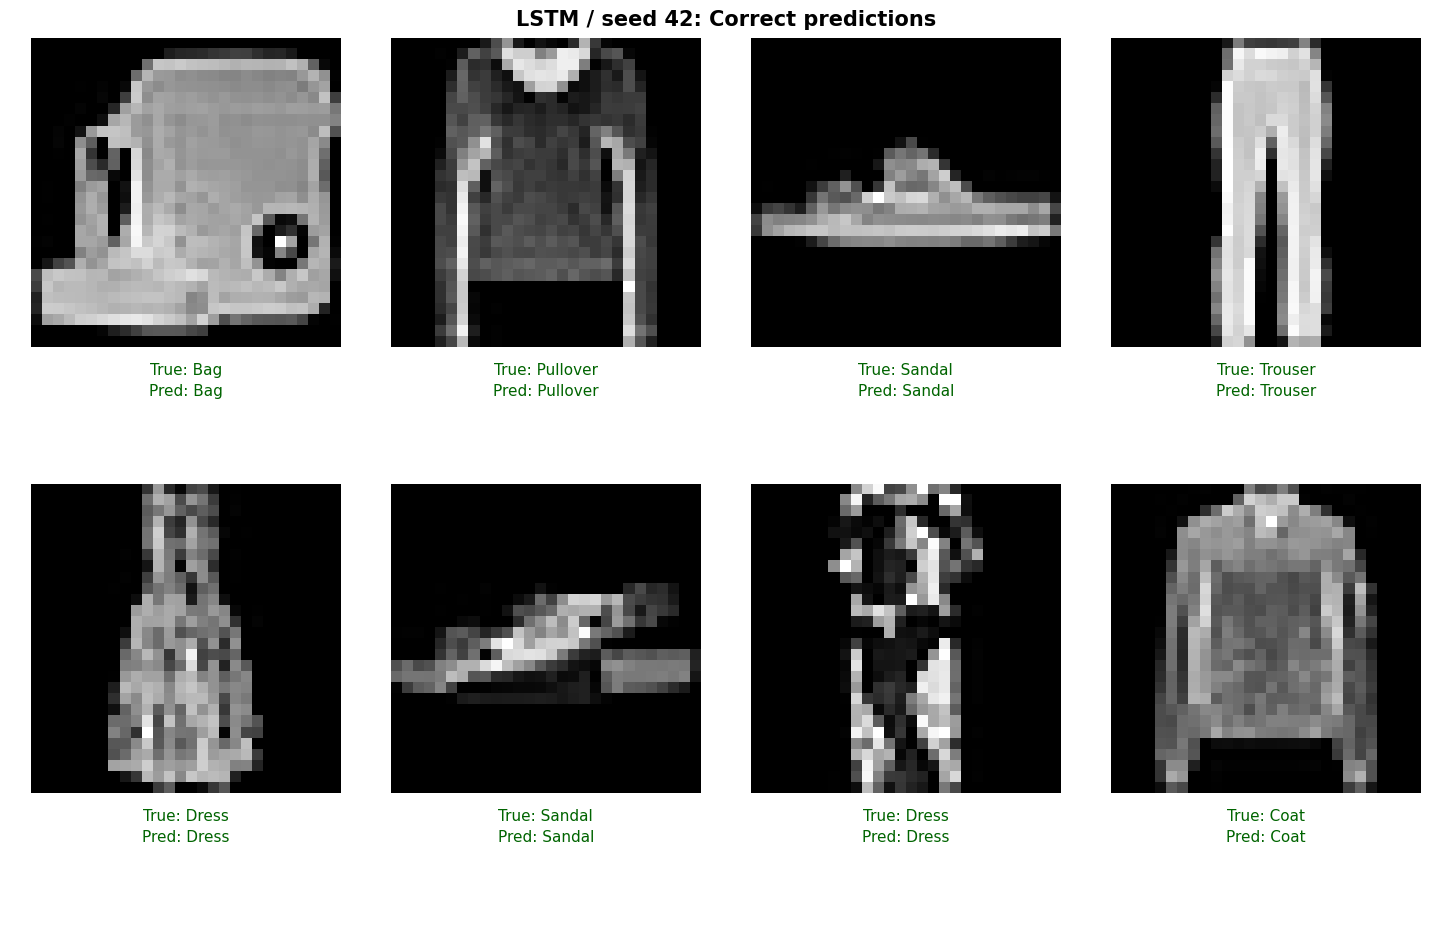

Saved: /content/fmnist_multiseed_42_43_44/Baseline_LSTM_seed42_Correct.png


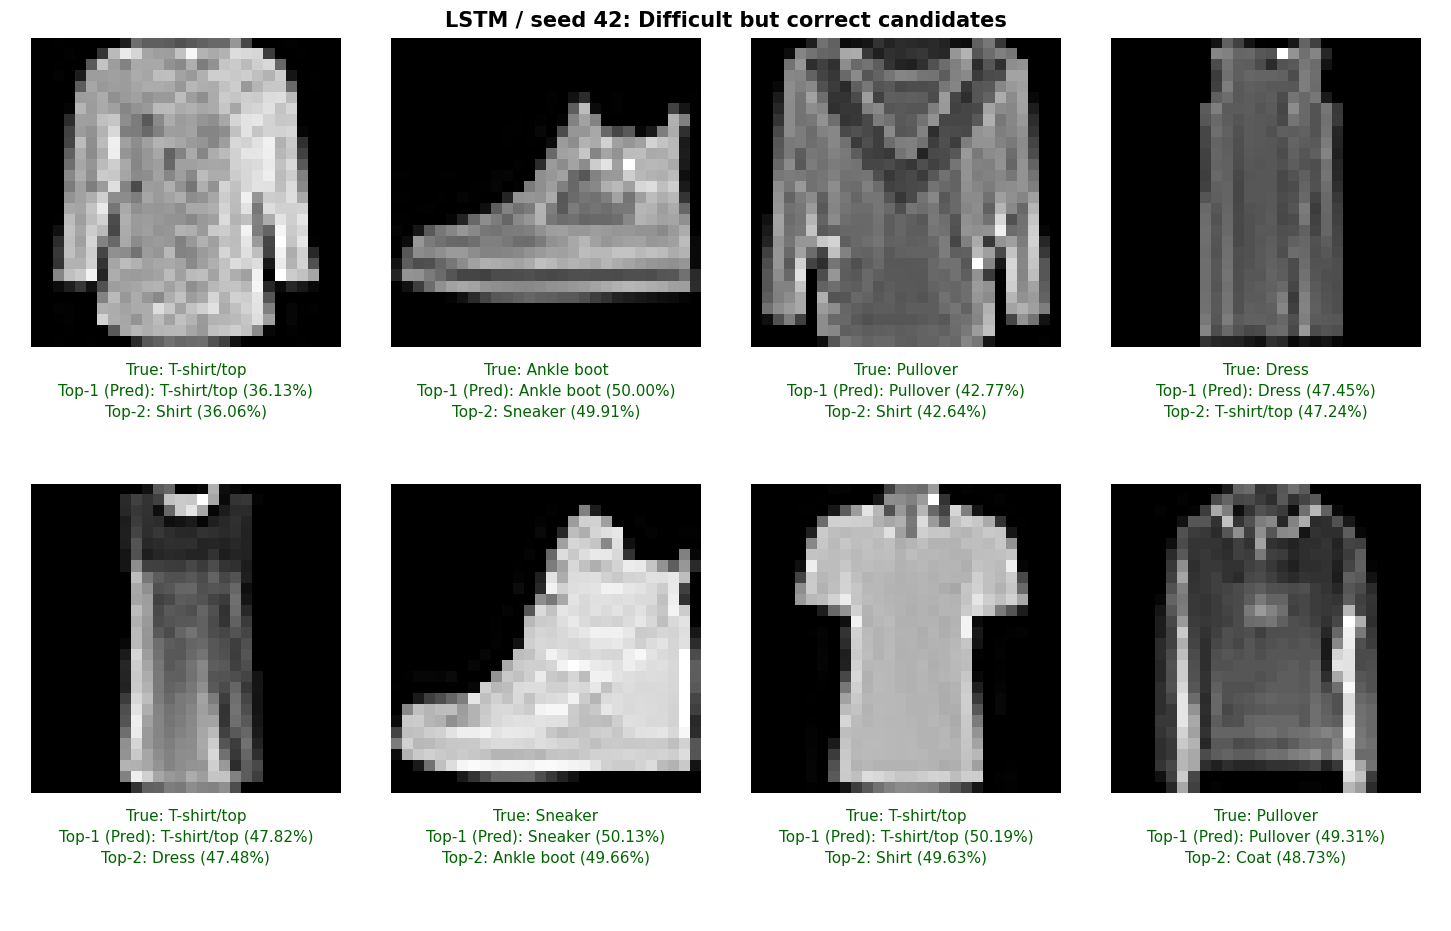

Saved: /content/fmnist_multiseed_42_43_44/Baseline_LSTM_seed42_Difficult_correct_candidates.png


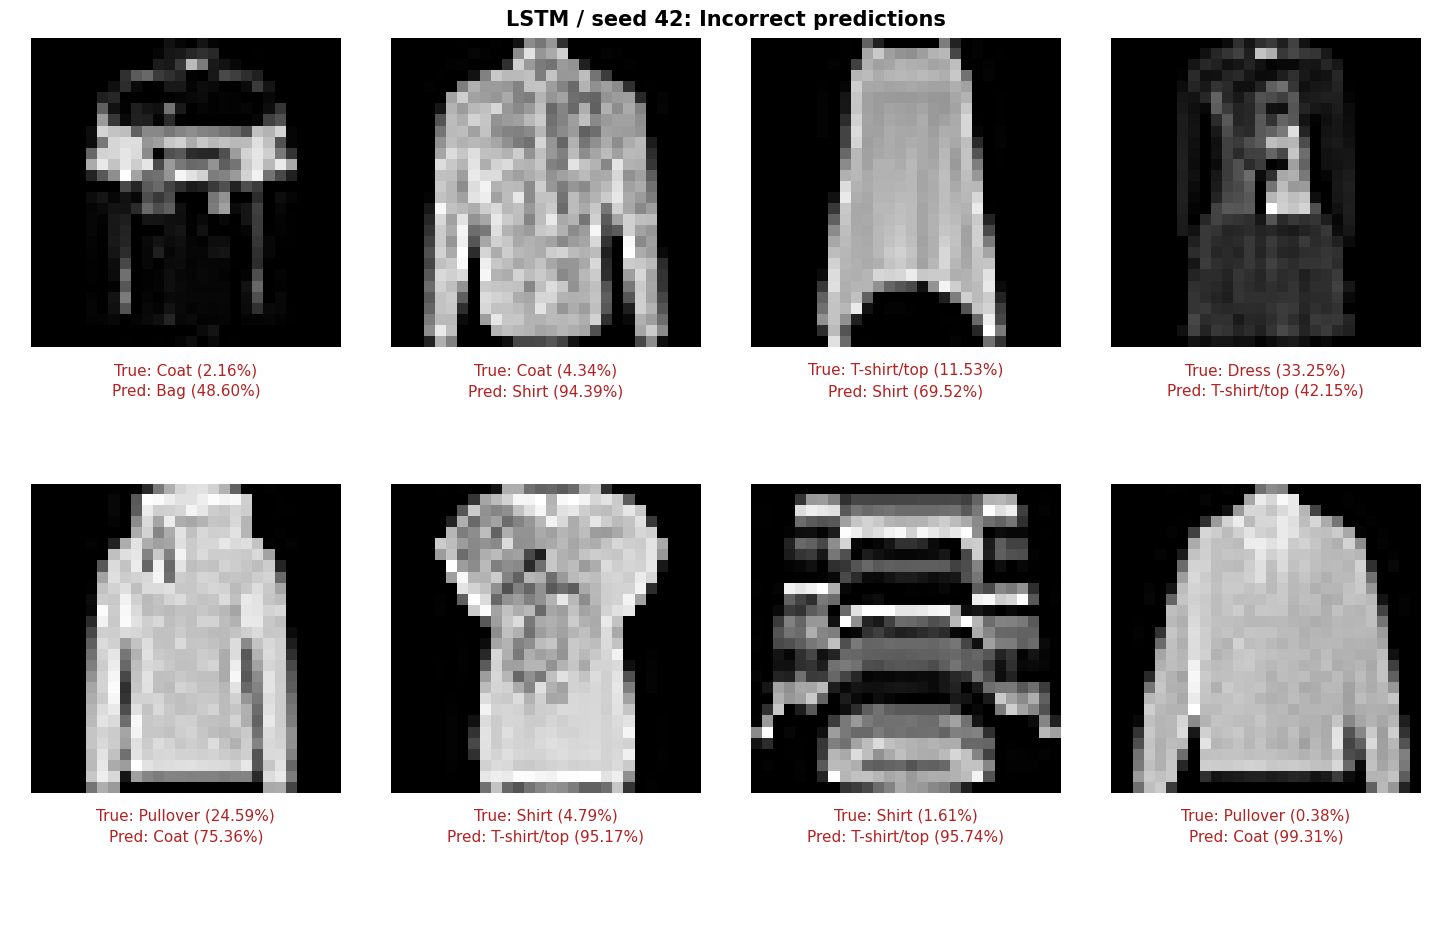

Saved: /content/fmnist_multiseed_42_43_44/Baseline_LSTM_seed42_Failures.png

Qualitative results: Transformer, seed 42


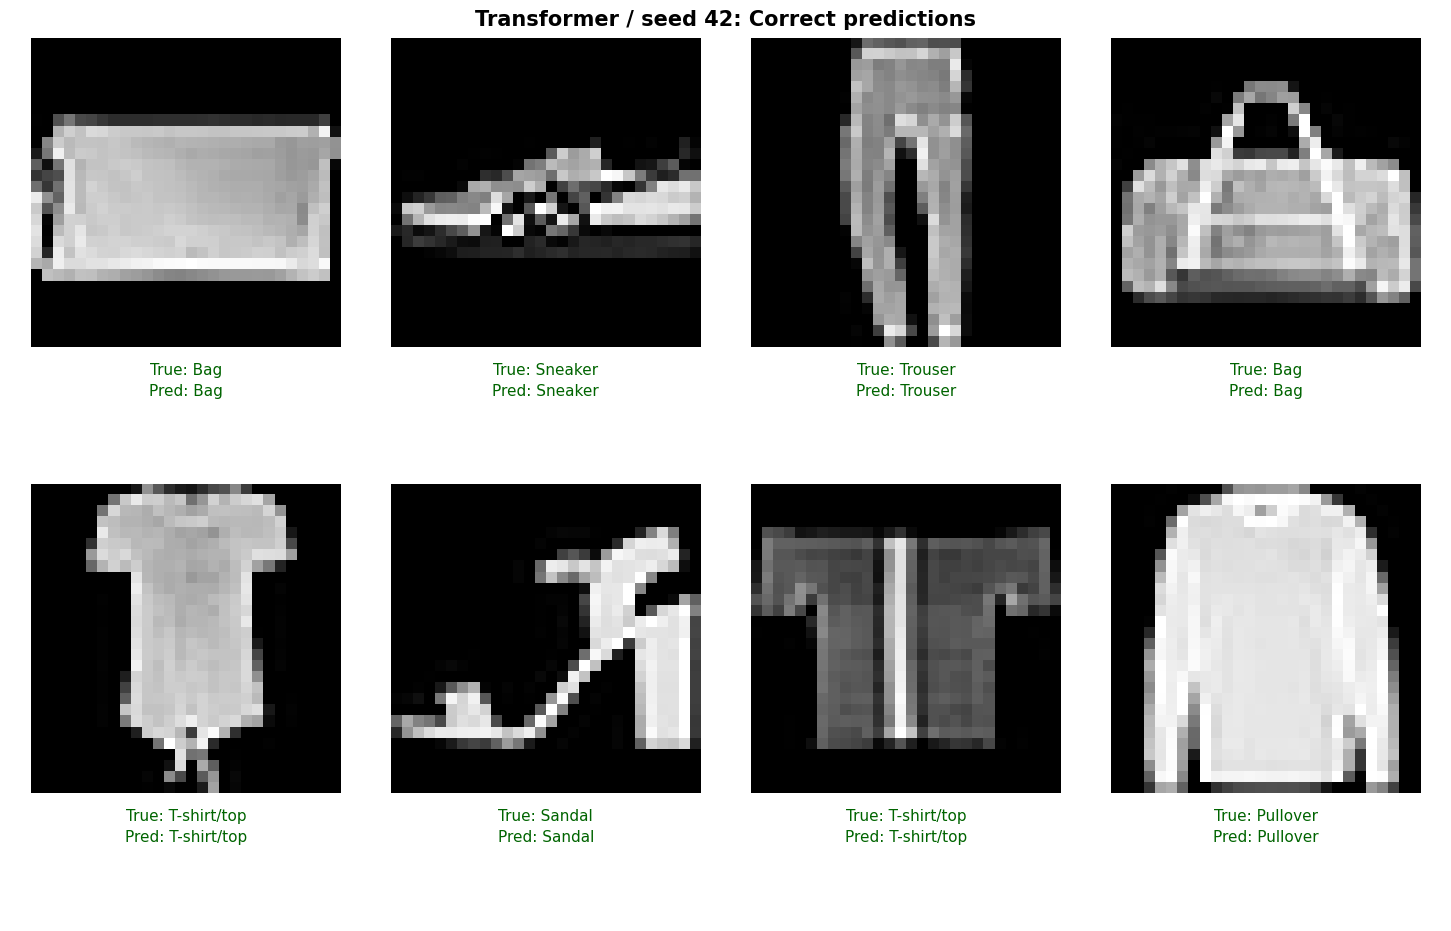

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Transformer_seed42_Correct.png


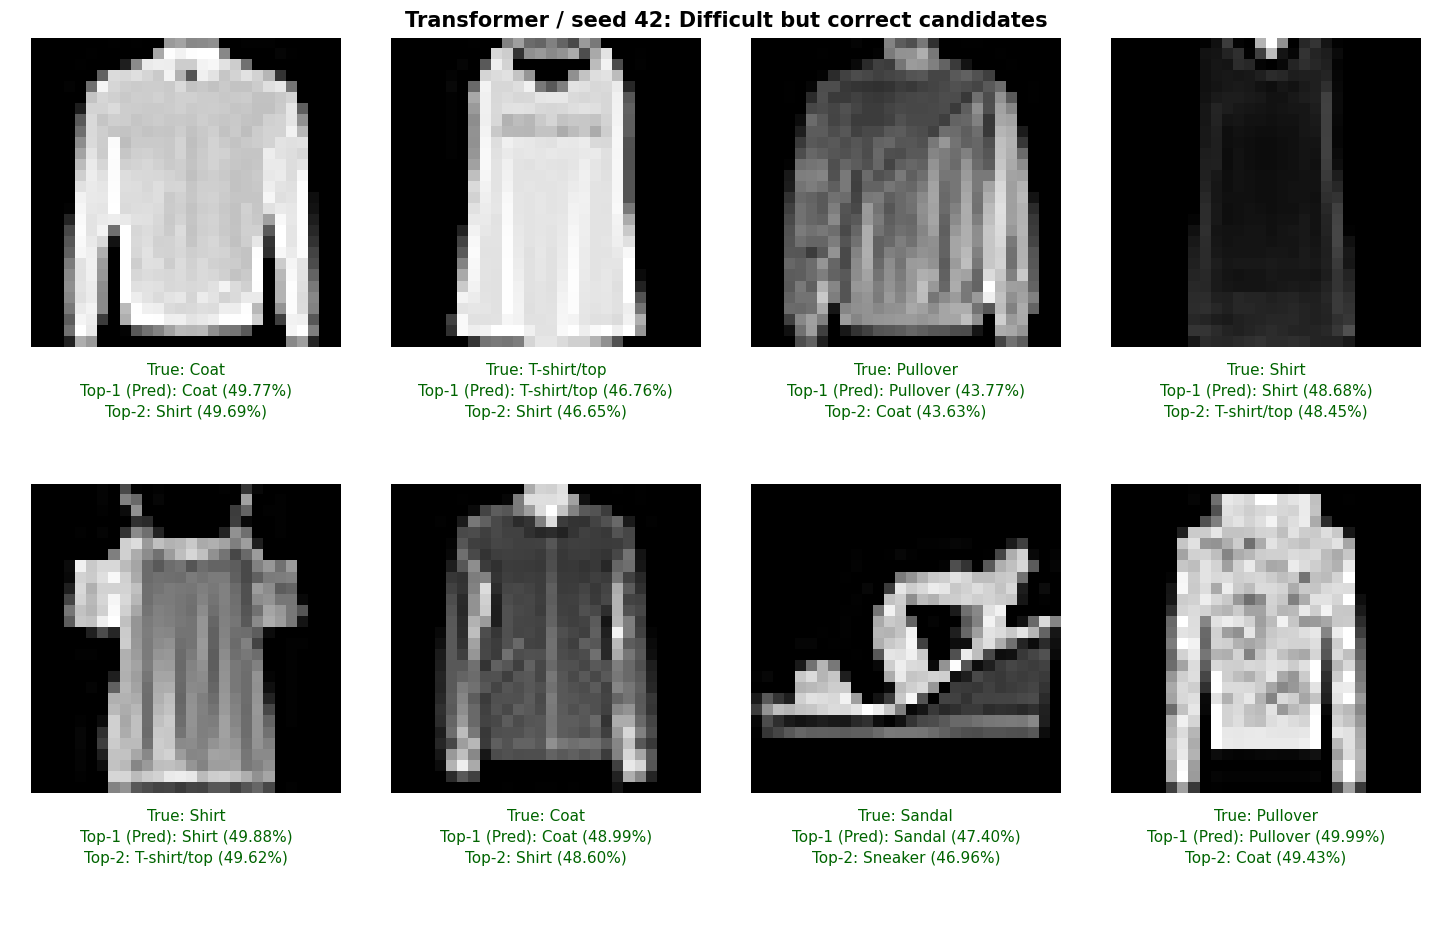

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Transformer_seed42_Difficult_correct_candidates.png


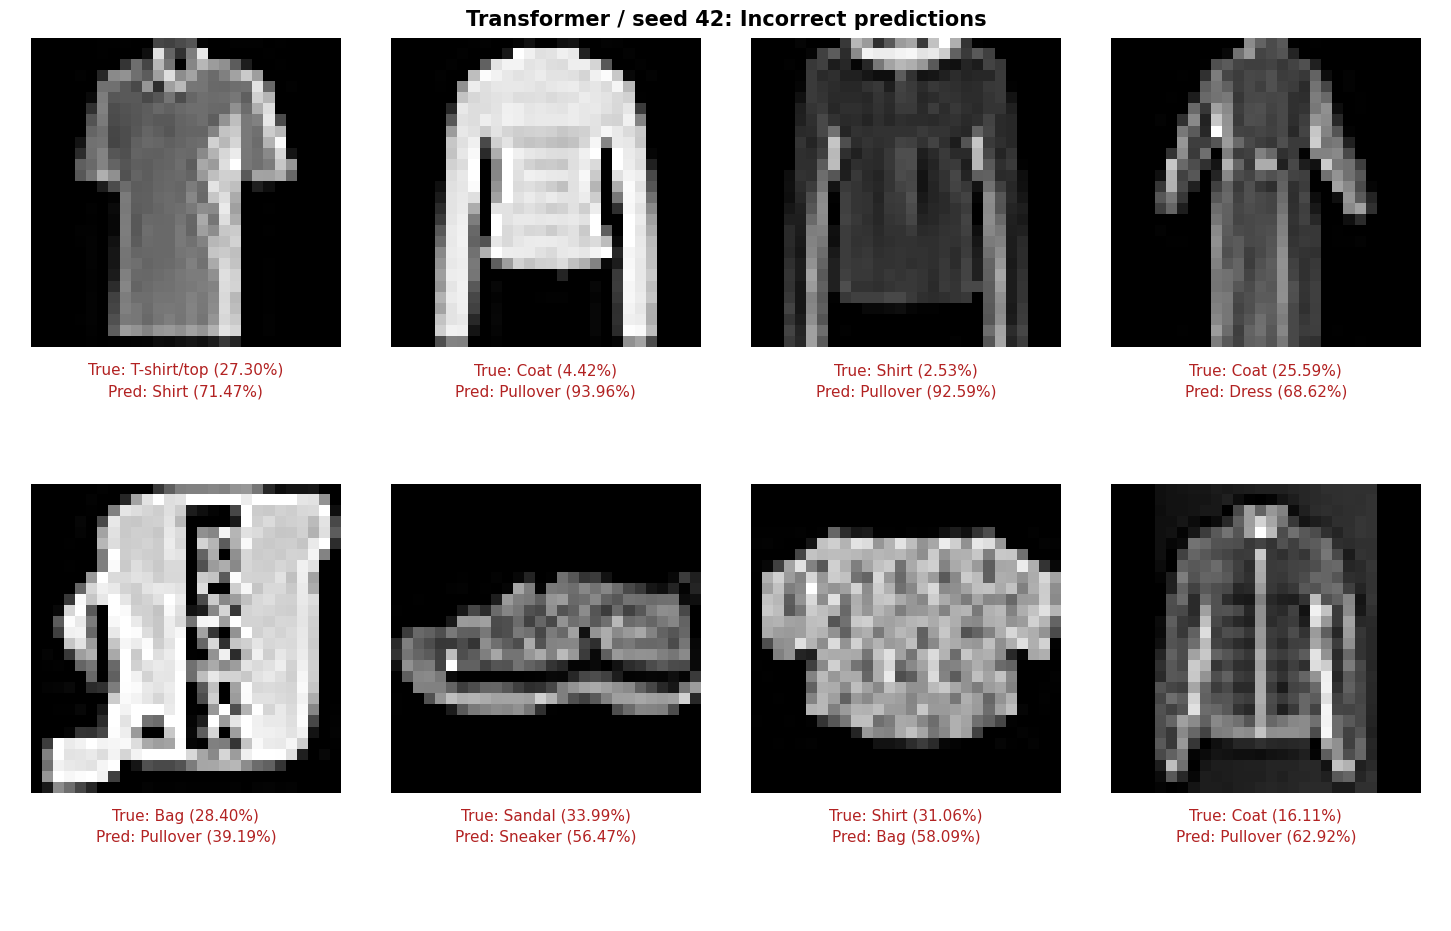

Saved: /content/fmnist_multiseed_42_43_44/Baseline_Transformer_seed42_Failures.png


In [31]:
VIS_MODELS = ["Linear", "MLP", "CNN", "LSTM", "Transformer"]
VIS_VARIANT = "Baseline"
VIS_SEED = 42
VIS_N_EXAMPLES = 8

os.makedirs(RUNTIME_FIG_DIR, exist_ok=True)

for name in VIS_MODELS:
  key = (VIS_VARIANT, name, VIS_SEED)

  if key not in evaluated_runs:
    print("Representative run is unavailable:", key)
    continue

  print(f"\nQualitative results: {name}, seed {VIS_SEED}")

  model, _, _ = load_model_checkpoint(
    name, VIS_SEED, VIS_VARIANT
  )
  model.eval()
  _, _, visual_loader = make_loaders()

  probabilities, labels_list = [], []

  with torch.no_grad():
    for images, labels in visual_loader:
      logits = model(images.to(DEVICE))
      probabilities.append(
        torch.softmax(logits, dim=1).cpu().numpy()
      )
      labels_list.append(labels.cpu().numpy())

  probabilities = np.concatenate(probabilities)
  labels = np.concatenate(labels_list)

  if not np.array_equal(labels, test_labels):
    raise ValueError(
      "Visualization loader does not match "
      "the original test-image order."
    )

  predictions = probabilities.argmax(axis=1)
  scores = probabilities.max(axis=1)

  top_two = np.sort(probabilities, axis=1)[:, -2:]
  gaps = top_two[:, 1] - top_two[:, 0]

  correct = np.flatnonzero(predictions == labels)
  wrong = np.flatnonzero(predictions != labels)
  difficult = correct[
    np.argsort(gaps[correct], kind="stable")
  ][:VIS_N_EXAMPLES]
  rng = np.random.default_rng(VIS_SEED)
  correct_pool = np.setdiff1d(correct, difficult)

  correct_examples = rng.choice(
    correct_pool,
    size=min(VIS_N_EXAMPLES, len(correct_pool)),
    replace=False
  )
  wrong_examples = rng.choice(
    wrong,
    size=min(VIS_N_EXAMPLES, len(wrong)),
    replace=False
  )

  groups = [
    ("Correct", "Correct predictions", correct_examples),
    (
      "Difficult_correct_candidates",
      "Difficult but correct candidates",
      difficult
    ),
    ("Failures", "Incorrect predictions", wrong_examples)
  ]

  for kind, title, indices in groups:
    if len(indices) == 0:
      print(f"No examples: {name} / {kind}")
      continue

    ncols = min(4, len(indices))
    nrows = int(np.ceil(len(indices) / ncols))

    fig = plt.figure(
      figsize=(3.6 * ncols, 4.6 * nrows),
      constrained_layout=True
    )
    outer_grid = fig.add_gridspec(
      nrows, ncols,
      wspace=0.08,
      hspace=0.12
    )

    for position, idx in enumerate(indices):
      row, col = divmod(position, ncols)

      inner_grid = outer_grid[row, col].subgridspec(
        2, 1,
        height_ratios=[3.0, 1.15],
        hspace=0.02
      )

      image_ax = fig.add_subplot(inner_grid[0])
      text_ax = fig.add_subplot(inner_grid[1])

      image_ax.imshow(
        test_images[idx],
        cmap="gray",
        interpolation="nearest"
      )
      image_ax.axis("off")
      text_ax.axis("off")

      true_id = int(labels[idx])
      pred_id = int(predictions[idx])

      true_name = CLASS_NAMES[true_id]
      pred_name = CLASS_NAMES[pred_id]

      if kind == "Correct":
        annotation = (
          f"True: {true_name}\n"
          f"Pred: {pred_name}"
        )
        text_color = "darkgreen"

      elif kind == "Difficult_correct_candidates":
        top_ids = np.argsort(
          -probabilities[idx], kind="stable"
        )[:2]

        top1_id, top2_id = map(int, top_ids)
        top1_score = 100 * probabilities[idx, top1_id]
        top2_score = 100 * probabilities[idx, top2_id]

        annotation = (
          f"True: {true_name}\n"
          f"Top-1 (Pred): {CLASS_NAMES[top1_id]} "
          f"({top1_score:.2f}%)\n"
          f"Top-2: {CLASS_NAMES[top2_id]} "
          f"({top2_score:.2f}%)"
        )
        text_color = "darkgreen"

      else:
        # So sánh softmax của nhãn dự đoán và nhãn thật
        pred_score = 100 * probabilities[idx, pred_id]
        true_score = 100 * probabilities[idx, true_id]

        annotation = (
          f"True: {true_name} ({true_score:.2f}%)\n"
          f"Pred: {pred_name} ({pred_score:.2f}%)"
        )
        text_color = "firebrick"

      text_ax.text(
        0.5, 0.95,
        annotation,
        transform=text_ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
        linespacing=1.5,
        color=text_color
      )

    fig.suptitle(
      f"{name} / seed {VIS_SEED}: {title}",
      fontsize=15,
      fontweight="bold"
    )

    save_path = os.path.join(
      RUNTIME_FIG_DIR,
      f"{VIS_VARIANT}_{name}_seed{VIS_SEED}_{kind}.png"
    )

    fig.savefig(
      save_path,
      dpi=300,
      bbox_inches="tight",
      facecolor="white"
    )
    plt.show()
    plt.close(fig)

    print("Saved:", save_path)

  del model
  if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


## 17. Paired dropout-ablation comparison



In [32]:
def paired_ablation_tables(frame, expected_seeds, require_all=True):
  if frame.empty or not {"Baseline", "NoDropout"}.issubset(set(frame["variant"])):
    return pd.DataFrame(), pd.DataFrame()
  baseline = frame[frame["variant"] == "Baseline"]
  ablated = frame[frame["variant"] == "NoDropout"]
  paired = baseline.merge(ablated, on=["model", "seed"], suffixes=("_baseline", "_nodropout"), validate="one_to_one")
  if (paired["params_baseline"] != paired["params_nodropout"]).any():
    raise ValueError("Parameter counts changed in the dropout ablation.")
  deltas = paired[["model", "seed"]].copy()
  for key, scale, label in [
    ("test_accuracy", 100, "accuracy_delta_pp"),
    ("test_macro_f1", 100, "macro_f1_delta_pp"),
    ("test_loss", 1, "test_ce_delta"),
    ("train_time_per_epoch_sec", 1, "train_time_per_epoch_delta_sec"),
  ]:
    deltas[label] = scale * (paired[key + "_nodropout"] - paired[key + "_baseline"])
  rows = []
  for name, group in deltas.groupby("model", sort=False):
    if require_all and set(group["seed"]) != set(expected_seeds):
      continue
    row = {"model": name, "n_pairs": len(group)}
    for key in ["accuracy_delta_pp", "macro_f1_delta_pp", "test_ce_delta", "train_time_per_epoch_delta_sec"]:
      values = group[key].to_numpy(dtype=float)
      row[key + "_mean"] = float(np.mean(values))
      row[key + "_std"] = float(np.std(values, ddof=1)) if len(values) > 1 else float("nan")
    rows.append(row)
  return deltas, pd.DataFrame(rows)


paired_seed_deltas_df, paired_ablation_summary_df = paired_ablation_tables(
  run_results_df, TRAIN_SEEDS, REQUIRE_ALL_SEEDS
)
if not paired_seed_deltas_df.empty:
  paired_seed_deltas_df.to_csv(os.path.join(RESULTS_DIR, "paired_dropout_deltas_per_seed.csv"), index=False)
  paired_ablation_summary_df.to_csv(os.path.join(RESULTS_DIR, "paired_dropout_deltas_mean_std.csv"), index=False)
  print("NoDropout minus Baseline, paired within each seed:")
  print(paired_seed_deltas_df.round(6).to_string(index=False))
  print("\nMean and sample std of paired differences:")
  print(paired_ablation_summary_df.round(6).to_string(index=False))
else:
  print('Optional: enable RUN_VARIANTS = ["Baseline", "NoDropout"] and run both training groups for paired ablation results.')


NoDropout minus Baseline, paired within each seed:
      model  seed  accuracy_delta_pp  macro_f1_delta_pp  test_ce_delta  train_time_per_epoch_delta_sec
        MLP    42               1.06           1.150441      -0.031012                       -0.368399
        MLP    43               1.21           1.304096      -0.025224                        1.490993
        MLP    44               0.82           0.918887      -0.031025                       -2.112957
        CNN    42               0.67           0.662640      -0.015464                       -0.400523
        CNN    43               0.58           0.594963      -0.008838                        1.157633
        CNN    44               0.90           0.892100      -0.012836                       -2.348643
       LSTM    42               0.10           0.129393      -0.008323                       -0.447182
       LSTM    43              -0.22          -0.251310       0.001164                        0.930354
       LSTM    44     